# Data load

Loads two datasets for the window **2020-01-01 through 2026-10-12**:

- **EIA** monthly electricity retail sales for California (price, sales, revenue, customers), all sectors. [API docs](https://www.eia.gov/opendata/documentation.php).
- **Open-Meteo** historical daily weather for San Diego (temperature, precipitation, wind, solar radiation). [API docs](https://open-meteo.com/en/docs/historical-weather-api).

EIA reads `EIA_API_KEY` from `.env`. Open-Meteo non-commercial access does not use a key.

In [1]:
import json
import os
from pathlib import Path
from urllib.error import HTTPError
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import pandas as pd
from dotenv import load_dotenv


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / ".env.example").exists():
            return candidate
    return here


ROOT = find_repo_root()
load_dotenv(ROOT / ".env")

EIA_STATE = "CA"
SAN_DIEGO_LAT = 32.7157
SAN_DIEGO_LON = -117.1611
START_DATE = "2020-01-01"
END_DATE = "2026-10-12"

EIA_DATA_COLUMNS = ("price", "sales", "revenue", "customers")
WEATHER_DAILY_VARIABLES = (
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "precipitation_sum",
    "wind_speed_10m_max",
    "shortwave_radiation_sum",
    "sunshine_duration",
)

EIA_PAGE_SIZE = 5000
REQUEST_TIMEOUT_SECONDS = 120


def get_json(url: str) -> dict:
    request = Request(url, headers={"User-Agent": "EcoShift-Data1/1.0"})
    try:
        with urlopen(request, timeout=REQUEST_TIMEOUT_SECONDS) as response:
            payload = json.load(response)
    except HTTPError as exc:
        detail = exc.read().decode("utf-8", errors="replace")
        route = exc.url.split("?", 1)[0]
        raise RuntimeError(f"Request failed ({exc.code}) for {route}: {detail}") from None
    if isinstance(payload, dict) and payload.get("error") and "response" not in payload:
        raise RuntimeError(str(payload.get("reason") or payload.get("error")))
    return payload

## EIA electricity retail sales

Route `electricity/retail-sales`. Values come back as strings, so numeric columns are cast on load. The API returns at most 5,000 rows per call; this pages until `total` is covered.

In [2]:
def load_eia_retail_sales() -> pd.DataFrame:
    api_key = os.getenv("EIA_API_KEY")
    if not api_key:
        raise RuntimeError(
            "EIA_API_KEY is not set. Register at https://www.eia.gov/opendata/register.php "
            "and add EIA_API_KEY to .env in the repo root."
        )

    rows = []
    offset = 0
    total = None
    while total is None or offset < total:
        params = [
            ("api_key", api_key),
            ("frequency", "monthly"),
            ("start", START_DATE[:7]),
            ("end", END_DATE[:7]),
            ("facets[stateid][]", EIA_STATE),
            ("sort[0][column]", "period"),
            ("sort[0][direction]", "asc"),
            ("offset", str(offset)),
            ("length", str(EIA_PAGE_SIZE)),
        ]
        params.extend(("data[]", column) for column in EIA_DATA_COLUMNS)
        url = "https://api.eia.gov/v2/electricity/retail-sales/data?" + urlencode(params)
        payload = get_json(url)
        response = payload["response"]
        batch = response.get("data") or []
        total = int(response["total"])
        rows.extend(batch)
        offset += len(batch)
        if not batch:
            break

    frame = pd.DataFrame(rows)
    id_columns = {"period", "stateid", "stateDescription", "sectorid", "sectorName"}
    for column in frame.columns:
        if column in id_columns or str(column).endswith("-units"):
            continue
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame


eia_retail_sales = load_eia_retail_sales()
print(eia_retail_sales.shape)
eia_retail_sales.head()

(474, 13)


,period,stateid,stateDescription,sectorid,sectorName,price,sales,revenue,customers,price-units,sales-units,revenue-units,customers-units
0,2020-01,CA,California,ALL,all sectors,16.44,20562.24693,3380.01823,15910955,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers
1,2020-01,CA,California,COM,commercial,15.29,9098.34947,1390.87010,1753839,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers
2,2020-01,CA,California,IND,industrial,11.80,3527.73482,416.44309,150915,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers
3,2020-01,CA,California,OTH,other,0.00,0.00000,0.00000,0,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers
4,2020-01,CA,California,RES,residential,19.91,7872.76848,1567.28793,14006188,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers


## Open-Meteo historical weather

Daily reanalysis for downtown San Diego (`32.7157`, `-117.1611`), timezone `America/Los_Angeles`. The coordinates in the frame are the grid cell the API actually used.

In [3]:
def load_open_meteo_daily() -> pd.DataFrame:
    params = [
        ("latitude", str(SAN_DIEGO_LAT)),
        ("longitude", str(SAN_DIEGO_LON)),
        ("start_date", START_DATE),
        ("end_date", END_DATE),
        ("daily", ",".join(WEATHER_DAILY_VARIABLES)),
        ("timezone", "America/Los_Angeles"),
    ]
    url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(params)
    payload = get_json(url)
    frame = pd.DataFrame(payload["daily"])
    frame["time"] = pd.to_datetime(frame["time"])
    frame.insert(1, "latitude", payload["latitude"])
    frame.insert(2, "longitude", payload["longitude"])
    return frame


weather = load_open_meteo_daily()
print(weather.shape)
weather.head()

(2477, 10)


,time,latitude,longitude,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max,shortwave_radiation_sum,sunshine_duration
0,2020-01-01,32.724075,-117.14285,11.6,16.8,6.6,0.0,13.6,12.15,34399.10
1,2020-01-02,32.724075,-117.14285,12.5,17.9,8.5,0.0,20.0,12.34,35377.65
2,2020-01-03,32.724075,-117.14285,12.4,19.3,7.0,0.0,12.4,12.28,35424.60
3,2020-01-04,32.724075,-117.14285,11.9,17.3,7.2,0.0,14.8,12.68,35472.53
4,2020-01-05,32.724075,-117.14285,12.0,17.5,8.1,0.0,15.9,12.87,35521.36


## What you can do with these datasets

Both frames cover 2020 onward. EIA currently publishes through **2026-07** (474 rows: 79 months × 6 sectors). Weather runs daily through **2026-10-12** (2,477 days). A monthly join is limited to the months EIA has already released.

### EIA retail sales — `eia_retail_sales`

California electricity sold to end customers, one row per month and sector.

| Column | Meaning |
| --- | --- |
| `period` | Month, `YYYY-MM` |
| `sectorid` / `sectorName` | `RES` residential, `COM` commercial, `IND` industrial, `TRA` transportation, `OTH` other, `ALL` all sectors |
| `price` | Average retail price, cents per kilowatt-hour |
| `sales` | Electricity sold, million kilowatt-hours |
| `revenue` | Revenue from those sales, million dollars |
| `customers` | Number of customers |

With this frame you can:

- Plot each sector’s price, sales, revenue, and customer count from 2020-01 through 2026-07.
- Compare who is driving demand. Residential and commercial sales move with the calendar; industrial sales move more with economic activity.
- Measure seasonality. California sales usually rise in summer (cooling) and, for residential, again in winter.
- Check that `price × sales` is in the same ballpark as `revenue` (cents/kWh × million kWh → million dollars after dividing by 100). Large gaps are worth a closer look.
- Use `customers` as scale, and `sales / customers` as a rough monthly use per customer.
- Treat `ALL` as the statewide total. Keep it out of sector comparisons so it is not double-counted.

This route is demand and retail price. Generation by fuel (solar, wind, gas, nuclear) is a different EIA route, `electricity/electric-power-operational-data`, if you want supply later.

### Open-Meteo weather — `weather`

Daily reanalysis for the San Diego grid cell the API selected (about `32.72`, `-117.14`).

| Column | Unit |
| --- | --- |
| `time` | Local date, `America/Los_Angeles` |
| `temperature_2m_mean` / `_max` / `_min` | °C |
| `precipitation_sum` | mm |
| `wind_speed_10m_max` | km/h at 10 m |
| `shortwave_radiation_sum` | MJ/m², daily solar energy on a horizontal surface |
| `sunshine_duration` | seconds of sunshine |

With this frame you can:

- Summarize San Diego’s temperature, rain, wind, and sun over the full window, by day, month, or season.
- Build degree-day style features from `temperature_2m_max` and `temperature_2m_min` (hot days vs cool days).
- Treat `shortwave_radiation_sum` and `sunshine_duration` as the local solar resource.
- Treat `wind_speed_10m_max` as a surface-wind indicator. It is the daily maximum at 10 m, so it is a weak stand-in for turbine output at hub height.
- Flag extreme days: heat, heavy rain, high wind, very low sun.

### Using them together

EIA is monthly and statewide. Weather is daily and one coastal point. Aggregate weather to month, then merge on `period`:

1. Floor `weather["time"]` to month and format it as `YYYY-MM`.
2. Take the monthly mean of temperature, the sum of precipitation and radiation, and the max of wind.
3. Merge that onto `eia_retail_sales` for one sector at a time, usually `RES`.

Questions that merge can support:

- Do hotter months line up with higher residential `sales`?
- After you remove the seasonal cycle, is there still a temperature effect?
- Do dull, low-radiation months coincide with higher grid sales (less behind-the-meter rooftop solar, more purchased electricity)? `sales` is utility retail sales, so rooftop generation never appears in this EIA route.
- Can a simple monthly model of residential `sales` use temperature, radiation, and month-of-year?

Two limits to keep in the interpretation:

- San Diego weather will miss inland heat that still shows up in statewide California sales. A Sacramento or Fresno Open-Meteo series would be a better companion if the question is statewide demand.
- `price` mostly follows tariffs and regulation. Weather should line up more cleanly with `sales` than with `price`.

## Relationship survey

Graphs below are the pass over both frames for a first model. `OTH` is all zeros (no customers, no sales), so it is dropped anywhere a correlation would be undefined. Transportation is real but tiny: about 56 million kWh a month versus about 7,300 for residential.

Cooling and heating degree days use a **18°C** base (about 65°F). A day at 21°C adds 3 CDD; a day at 14°C adds 4 HDD. `hot_days` counts days with a high of at least 28°C. San Diego's coast only has 122 of those in this window, so CDD is the heat feature that actually varies.


# Data load

Loads two datasets for the window **2020-01-01 through 2026-10-12**:

- **EIA** monthly electricity retail sales for California (price, sales, revenue, customers), all sectors. [API docs](https://www.eia.gov/opendata/documentation.php).
- **Open-Meteo** historical daily weather for San Diego (temperature, precipitation, wind, solar radiation). [API docs](https://open-meteo.com/en/docs/historical-weather-api).

EIA reads `EIA_API_KEY` from `.env`. Open-Meteo non-commercial access does not use a key.

In [ ]:
import json
import os
from pathlib import Path
from urllib.error import HTTPError
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import pandas as pd
from dotenv import load_dotenv


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / ".env.example").exists():
            return candidate
    return here


ROOT = find_repo_root()
load_dotenv(ROOT / ".env")

EIA_STATE = "CA"
SAN_DIEGO_LAT = 32.7157
SAN_DIEGO_LON = -117.1611
START_DATE = "2020-01-01"
END_DATE = "2026-10-12"

EIA_DATA_COLUMNS = ("price", "sales", "revenue", "customers")
WEATHER_DAILY_VARIABLES = (
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "precipitation_sum",
    "wind_speed_10m_max",
    "shortwave_radiation_sum",
    "sunshine_duration",
)

EIA_PAGE_SIZE = 5000
REQUEST_TIMEOUT_SECONDS = 120


def get_json(url: str) -> dict:
    request = Request(url, headers={"User-Agent": "EcoShift-Data1/1.0"})
    try:
        with urlopen(request, timeout=REQUEST_TIMEOUT_SECONDS) as response:
            payload = json.load(response)
    except HTTPError as exc:
        detail = exc.read().decode("utf-8", errors="replace")
        route = exc.url.split("?", 1)[0]
        raise RuntimeError(f"Request failed ({exc.code}) for {route}: {detail}") from None
    if isinstance(payload, dict) and payload.get("error") and "response" not in payload:
        raise RuntimeError(str(payload.get("reason") or payload.get("error")))
    return payload

## EIA electricity retail sales

Route `electricity/retail-sales`. Values come back as strings, so numeric columns are cast on load. The API returns at most 5,000 rows per call; this pages until `total` is covered.

In [ ]:
def load_eia_retail_sales() -> pd.DataFrame:
    api_key = os.getenv("EIA_API_KEY")
    if not api_key:
        raise RuntimeError(
            "EIA_API_KEY is not set. Register at https://www.eia.gov/opendata/register.php "
            "and add EIA_API_KEY to .env in the repo root."
        )

    rows = []
    offset = 0
    total = None
    while total is None or offset < total:
        params = [
            ("api_key", api_key),
            ("frequency", "monthly"),
            ("start", START_DATE[:7]),
            ("end", END_DATE[:7]),
            ("facets[stateid][]", EIA_STATE),
            ("sort[0][column]", "period"),
            ("sort[0][direction]", "asc"),
            ("offset", str(offset)),
            ("length", str(EIA_PAGE_SIZE)),
        ]
        params.extend(("data[]", column) for column in EIA_DATA_COLUMNS)
        url = "https://api.eia.gov/v2/electricity/retail-sales/data?" + urlencode(params)
        payload = get_json(url)
        response = payload["response"]
        batch = response.get("data") or []
        total = int(response["total"])
        rows.extend(batch)
        offset += len(batch)
        if not batch:
            break

    frame = pd.DataFrame(rows)
    id_columns = {"period", "stateid", "stateDescription", "sectorid", "sectorName"}
    for column in frame.columns:
        if column in id_columns or str(column).endswith("-units"):
            continue
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame


eia_retail_sales = load_eia_retail_sales()
print(eia_retail_sales.shape)
eia_retail_sales.head()

(474, 13)


,period,stateid,stateDescription,sectorid,sectorName,price,sales,revenue,customers,price-units,sales-units,revenue-units,customers-units
0,2020-01,CA,California,ALL,all sectors,16.44,20562.24693,3380.01823,15910955,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers
1,2020-01,CA,California,COM,commercial,15.29,9098.34947,1390.87010,1753839,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers
2,2020-01,CA,California,IND,industrial,11.80,3527.73482,416.44309,150915,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers
3,2020-01,CA,California,OTH,other,0.00,0.00000,0.00000,0,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers
4,2020-01,CA,California,RES,residential,19.91,7872.76848,1567.28793,14006188,cents per kilowatt-hour,million kilowatt hours,million dollars,number of customers


## Open-Meteo historical weather

Daily reanalysis for downtown San Diego (`32.7157`, `-117.1611`), timezone `America/Los_Angeles`. The coordinates in the frame are the grid cell the API actually used.

In [ ]:
def load_open_meteo_daily() -> pd.DataFrame:
    params = [
        ("latitude", str(SAN_DIEGO_LAT)),
        ("longitude", str(SAN_DIEGO_LON)),
        ("start_date", START_DATE),
        ("end_date", END_DATE),
        ("daily", ",".join(WEATHER_DAILY_VARIABLES)),
        ("timezone", "America/Los_Angeles"),
    ]
    url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(params)
    payload = get_json(url)
    frame = pd.DataFrame(payload["daily"])
    frame["time"] = pd.to_datetime(frame["time"])
    frame.insert(1, "latitude", payload["latitude"])
    frame.insert(2, "longitude", payload["longitude"])
    return frame


weather = load_open_meteo_daily()
print(weather.shape)
weather.head()

(2477, 10)


,time,latitude,longitude,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max,shortwave_radiation_sum,sunshine_duration
0,2020-01-01,32.724075,-117.14285,11.6,16.8,6.6,0.0,13.6,12.15,34399.10
1,2020-01-02,32.724075,-117.14285,12.5,17.9,8.5,0.0,20.0,12.34,35377.65
2,2020-01-03,32.724075,-117.14285,12.4,19.3,7.0,0.0,12.4,12.28,35424.60
3,2020-01-04,32.724075,-117.14285,11.9,17.3,7.2,0.0,14.8,12.68,35472.53
4,2020-01-05,32.724075,-117.14285,12.0,17.5,8.1,0.0,15.9,12.87,35521.36


## What you can do with these datasets

Both frames cover 2020 onward. EIA currently publishes through **2026-07** (474 rows: 79 months × 6 sectors). Weather runs daily through **2026-10-12** (2,477 days). A monthly join is limited to the months EIA has already released.

### EIA retail sales — `eia_retail_sales`

California electricity sold to end customers, one row per month and sector.

| Column | Meaning |
| --- | --- |
| `period` | Month, `YYYY-MM` |
| `sectorid` / `sectorName` | `RES` residential, `COM` commercial, `IND` industrial, `TRA` transportation, `OTH` other, `ALL` all sectors |
| `price` | Average retail price, cents per kilowatt-hour |
| `sales` | Electricity sold, million kilowatt-hours |
| `revenue` | Revenue from those sales, million dollars |
| `customers` | Number of customers |

With this frame you can:

- Plot each sector’s price, sales, revenue, and customer count from 2020-01 through 2026-07.
- Compare who is driving demand. Residential and commercial sales move with the calendar; industrial sales move more with economic activity.
- Measure seasonality. California sales usually rise in summer (cooling) and, for residential, again in winter.
- Check that `price × sales` is in the same ballpark as `revenue` (cents/kWh × million kWh → million dollars after dividing by 100). Large gaps are worth a closer look.
- Use `customers` as scale, and `sales / customers` as a rough monthly use per customer.
- Treat `ALL` as the statewide total. Keep it out of sector comparisons so it is not double-counted.

This route is demand and retail price. Generation by fuel (solar, wind, gas, nuclear) is a different EIA route, `electricity/electric-power-operational-data`, if you want supply later.

### Open-Meteo weather — `weather`

Daily reanalysis for the San Diego grid cell the API selected (about `32.72`, `-117.14`).

| Column | Unit |
| --- | --- |
| `time` | Local date, `America/Los_Angeles` |
| `temperature_2m_mean` / `_max` / `_min` | °C |
| `precipitation_sum` | mm |
| `wind_speed_10m_max` | km/h at 10 m |
| `shortwave_radiation_sum` | MJ/m², daily solar energy on a horizontal surface |
| `sunshine_duration` | seconds of sunshine |

With this frame you can:

- Summarize San Diego’s temperature, rain, wind, and sun over the full window, by day, month, or season.
- Build degree-day style features from `temperature_2m_max` and `temperature_2m_min` (hot days vs cool days).
- Treat `shortwave_radiation_sum` and `sunshine_duration` as the local solar resource.
- Treat `wind_speed_10m_max` as a surface-wind indicator. It is the daily maximum at 10 m, so it is a weak stand-in for turbine output at hub height.
- Flag extreme days: heat, heavy rain, high wind, very low sun.

### Using them together

EIA is monthly and statewide. Weather is daily and one coastal point. Aggregate weather to month, then merge on `period`:

1. Floor `weather["time"]` to month and format it as `YYYY-MM`.
2. Take the monthly mean of temperature, the sum of precipitation and radiation, and the max of wind.
3. Merge that onto `eia_retail_sales` for one sector at a time, usually `RES`.

Questions that merge can support:

- Do hotter months line up with higher residential `sales`?
- After you remove the seasonal cycle, is there still a temperature effect?
- Do dull, low-radiation months coincide with higher grid sales (less behind-the-meter rooftop solar, more purchased electricity)? `sales` is utility retail sales, so rooftop generation never appears in this EIA route.
- Can a simple monthly model of residential `sales` use temperature, radiation, and month-of-year?

Two limits to keep in the interpretation:

- San Diego weather will miss inland heat that still shows up in statewide California sales. A Sacramento or Fresno Open-Meteo series would be a better companion if the question is statewide demand.
- `price` mostly follows tariffs and regulation. Weather should line up more cleanly with `sales` than with `price`.

## Relationship survey

Graphs below are the pass over both frames for a first model. `OTH` is all zeros (no customers, no sales), so it is dropped anywhere a correlation would be undefined. Transportation is real but tiny: about 56 million kWh a month versus about 7,300 for residential.

Cooling and heating degree days use a **18°C** base (about 65°F). A day at 21°C adds 3 CDD; a day at 14°C adds 4 HDD. `hot_days` counts days with a high of at least 28°C. San Diego's coast only has 122 of those in this window, so CDD is the heat feature that actually varies.


In [ ]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

SECTORS = ["RES", "COM", "IND", "TRA", "OTH", "ALL"]
MAIN_SECTORS = ["RES", "COM", "IND", "ALL"]
COMPARE_SECTORS = ["RES", "COM", "IND", "TRA", "ALL"]
SECTOR_COLORS = dict(zip(SECTORS, sns.color_palette("tab10", n_colors=len(SECTORS))))

WX = [
    "temp_mean",
    "temp_max",
    "temp_min",
    "diurnal_range",
    "precip_mm",
    "wind_max",
    "wind_mean",
    "radiation_mj",
    "sunshine_hours",
    "cdd",
    "hdd",
    "hot_days",
    "cold_days",
]
WX_LABELS = {
    "temp_mean": "Mean temp (°C)",
    "temp_max": "Max temp (°C)",
    "temp_min": "Min temp (°C)",
    "diurnal_range": "Diurnal range (°C)",
    "precip_mm": "Precip (mm)",
    "wind_max": "Max wind (km/h)",
    "wind_mean": "Mean of daily max wind (km/h)",
    "radiation_mj": "Solar radiation (MJ/m²)",
    "sunshine_hours": "Sunshine (hours)",
    "cdd": "Cooling degree days",
    "hdd": "Heating degree days",
    "hot_days": "Days ≥ 28°C",
    "cold_days": "Days with min ≤ 8°C",
}

eia = eia_retail_sales.copy()
eia["period_dt"] = pd.to_datetime(eia["period"])
eia["year"] = eia["period_dt"].dt.year
eia["month"] = eia["period_dt"].dt.month
eia["kwh_per_customer"] = np.where(
    eia["customers"] > 0,
    eia["sales"] * 1_000_000 / eia["customers"],
    np.nan,
)

daily = weather.copy()
daily["cdd"] = (daily["temperature_2m_mean"] - 18).clip(lower=0)
daily["hdd"] = (18 - daily["temperature_2m_mean"]).clip(lower=0)
daily["diurnal_range"] = daily["temperature_2m_max"] - daily["temperature_2m_min"]
daily["sunshine_hours"] = daily["sunshine_duration"] / 3600
daily["period"] = daily["time"].dt.strftime("%Y-%m")
daily["month"] = daily["time"].dt.month
daily["year"] = daily["time"].dt.year

monthly_weather = daily.groupby("period", as_index=False).agg(
    temp_mean=("temperature_2m_mean", "mean"),
    temp_max=("temperature_2m_max", "max"),
    temp_min=("temperature_2m_min", "min"),
    diurnal_range=("diurnal_range", "mean"),
    precip_mm=("precipitation_sum", "sum"),
    wind_max=("wind_speed_10m_max", "max"),
    wind_mean=("wind_speed_10m_max", "mean"),
    radiation_mj=("shortwave_radiation_sum", "sum"),
    sunshine_hours=("sunshine_hours", "sum"),
    cdd=("cdd", "sum"),
    hdd=("hdd", "sum"),
    hot_days=("temperature_2m_max", lambda s: int((s >= 28).sum())),
    cold_days=("temperature_2m_min", lambda s: int((s <= 8).sum())),
)
monthly_weather["period_dt"] = pd.to_datetime(monthly_weather["period"])
monthly_weather["month"] = monthly_weather["period_dt"].dt.month
monthly_weather["year"] = monthly_weather["period_dt"].dt.year

panel = eia.merge(
    monthly_weather.drop(columns=["period_dt", "month", "year"]),
    on="period",
    how="inner",
)
print(f"panel {panel.shape[0]} rows, {panel['period'].min()} to {panel['period'].max()}")
print(f"daily weather {daily.shape[0]} days, monthly weather {monthly_weather.shape[0]} months")


def small_multiples(frame, y, title, ylabel, sectors=SECTORS, logy=False):
    ncols = 3 if len(sectors) > 3 else len(sectors)
    nrows = int(np.ceil(len(sectors) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.1 * nrows), sharex=True, squeeze=False)
    flat = axes.ravel()
    for ax, sector in zip(flat, sectors):
        part = frame[frame["sectorid"] == sector].sort_values("period_dt")
        ax.plot(part["period_dt"], part[y], color=SECTOR_COLORS[sector], linewidth=1.5)
        ax.set_title(sector)
        if logy:
            ax.set_yscale("log")
        ax.tick_params(axis="x", labelrotation=30)
        if part[y].nunique(dropna=True) <= 1:
            ax.set_ylim(-1, 1)
    for ax in flat[len(sectors):]:
        ax.set_visible(False)
    fig.suptitle(title, y=1.02)
    fig.supylabel(ylabel)
    fig.tight_layout()


def heatmap(frame, title, figsize=(10, 4.2), fmt=".2f"):
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        frame,
        annot=True,
        fmt=fmt,
        cmap="vlag",
        center=0,
        linewidths=0.4,
        ax=ax,
        annot_kws={"size": 8},
    )
    ax.set_title(title)
    fig.tight_layout()


def cross_corr(frame, target, method="pearson"):
    rows = {}
    for sector, group in frame.groupby("sectorid"):
        if sector == "OTH" or group[target].std(skipna=True) == 0:
            continue
        rows[sector] = group[WX + [target]].corr(method=method)[target].drop(target)
    return pd.DataFrame(rows).T.reindex(COMPARE_SECTORS)


def month_adjusted_corr(frame, target):
    rows = {}
    for sector, group in frame.groupby("sectorid"):
        if sector == "OTH":
            continue
        group = group.copy()
        columns = WX + [target]
        for column in columns:
            group[column] = group[column] - group.groupby("month")[column].transform("mean")
        if group[target].std(skipna=True) == 0:
            continue
        rows[sector] = group[columns].corr()[target].drop(target)
    return pd.DataFrame(rows).T.reindex(COMPARE_SECTORS)


panel 474 rows, 2020-01 to 2026-07
daily weather 2477 days, monthly weather 82 months


## EIA, on its own

Each sector gets its own y-axis so transportation and the empty `OTH` series do not flatten the others. The index chart then puts RES, COM, IND, and ALL on one scale (value divided by that sector's own mean) so the seasonal shapes can be compared.


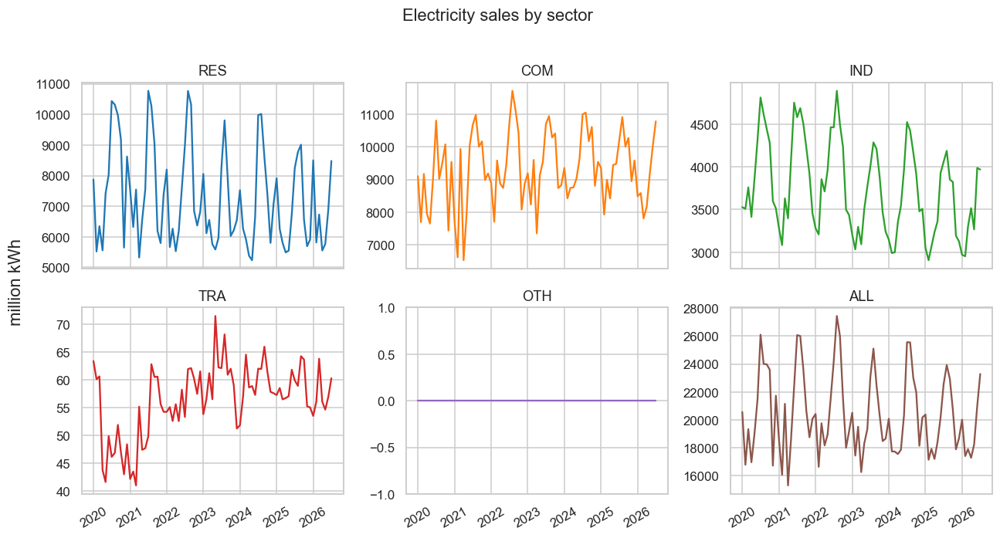

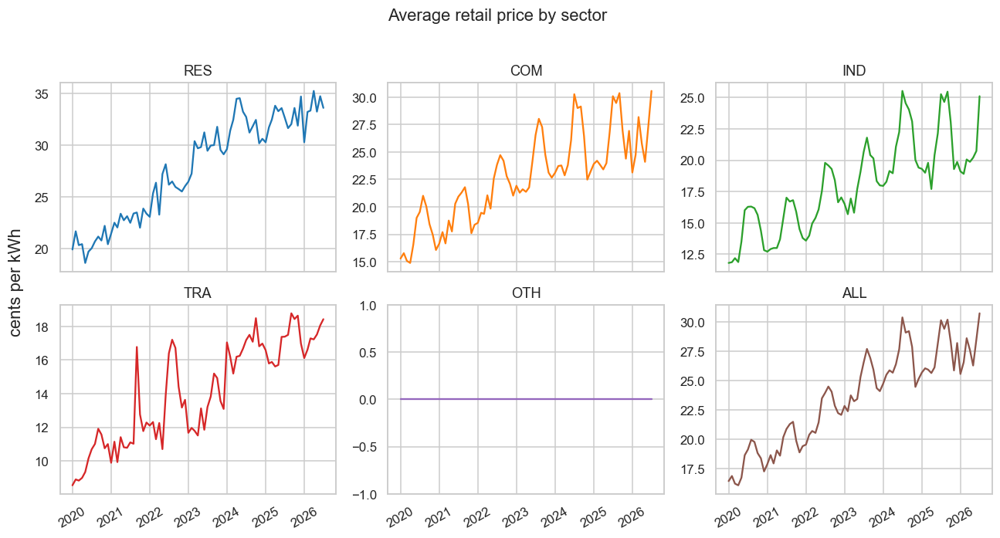

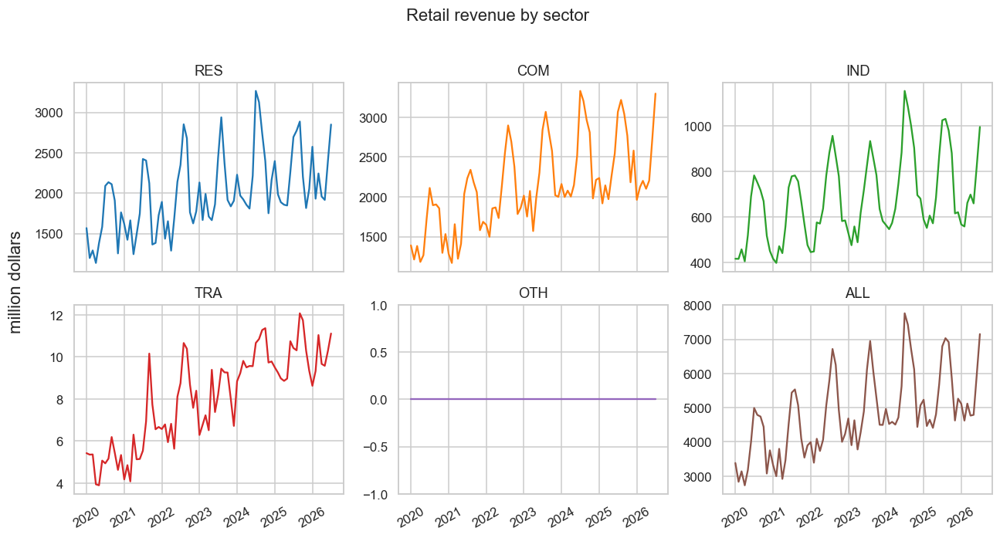

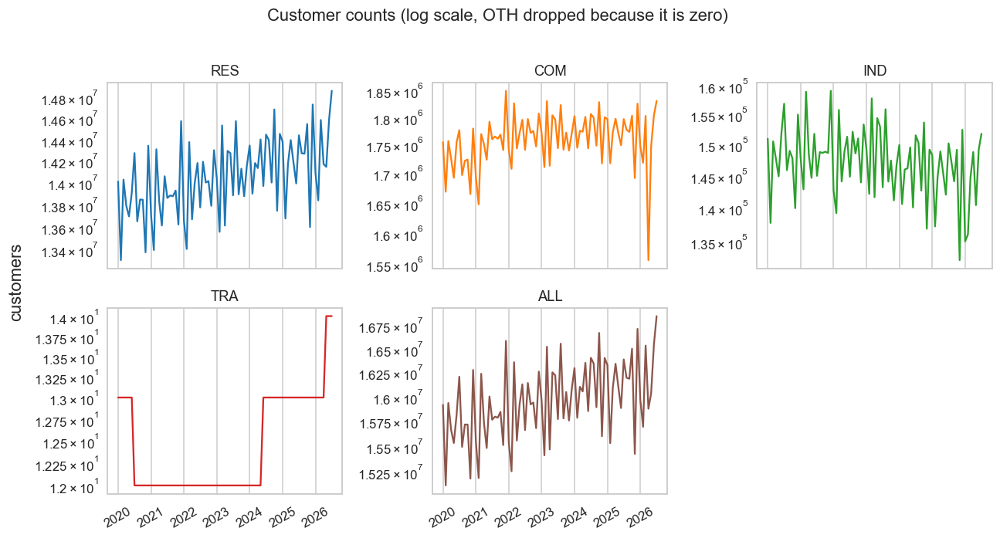

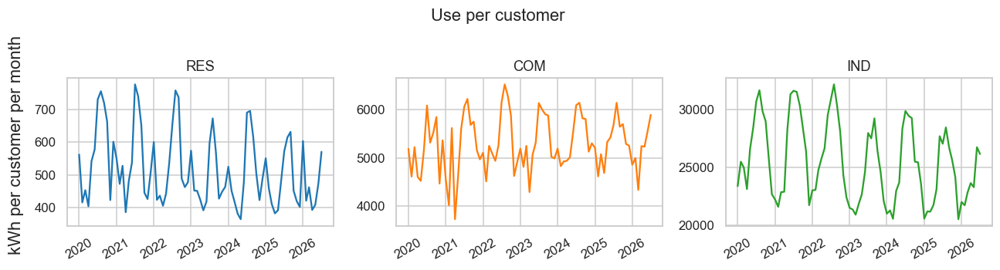

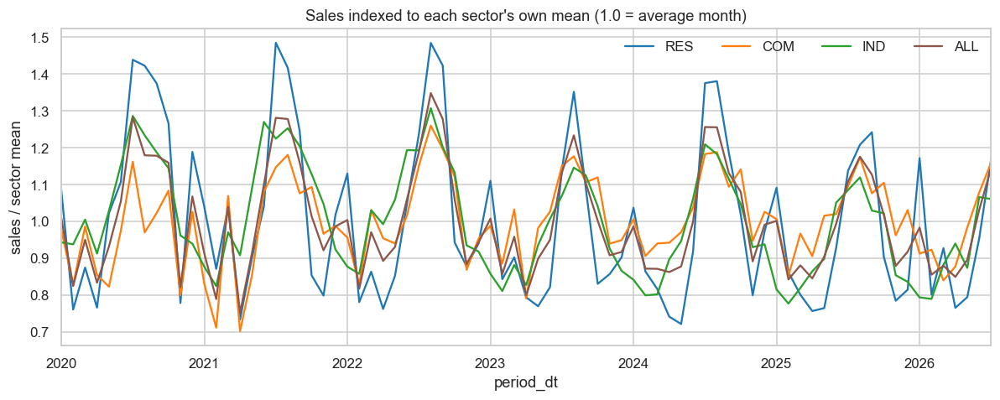

In [ ]:
small_multiples(eia, "sales", "Electricity sales by sector", "million kWh")
small_multiples(eia, "price", "Average retail price by sector", "cents per kWh")
small_multiples(eia, "revenue", "Retail revenue by sector", "million dollars")
small_multiples(
    eia[eia["customers"] > 0],
    "customers",
    "Customer counts (log scale, OTH dropped because it is zero)",
    "customers",
    sectors=["RES", "COM", "IND", "TRA", "ALL"],
    logy=True,
)
small_multiples(
    eia[eia["sectorid"].isin(["RES", "COM", "IND"])],
    "kwh_per_customer",
    "Use per customer",
    "kWh per customer per month",
    sectors=["RES", "COM", "IND"],
)

indexed = (
    eia[eia["sectorid"].isin(MAIN_SECTORS)]
    .assign(index=lambda frame: frame["sales"] / frame.groupby("sectorid")["sales"].transform("mean"))
    .pivot(index="period_dt", columns="sectorid", values="index")[MAIN_SECTORS]
)
ax = indexed.plot(
    figsize=(11, 4.5),
    color=[SECTOR_COLORS[sector] for sector in MAIN_SECTORS],
    title="Sales indexed to each sector's own mean (1.0 = average month)",
)
ax.set_ylabel("sales / sector mean")
ax.legend(title=None, ncol=4, frameon=False)
ax.figure.tight_layout()


Text(0.5, 0.98, 'Price versus sales, colored by month')

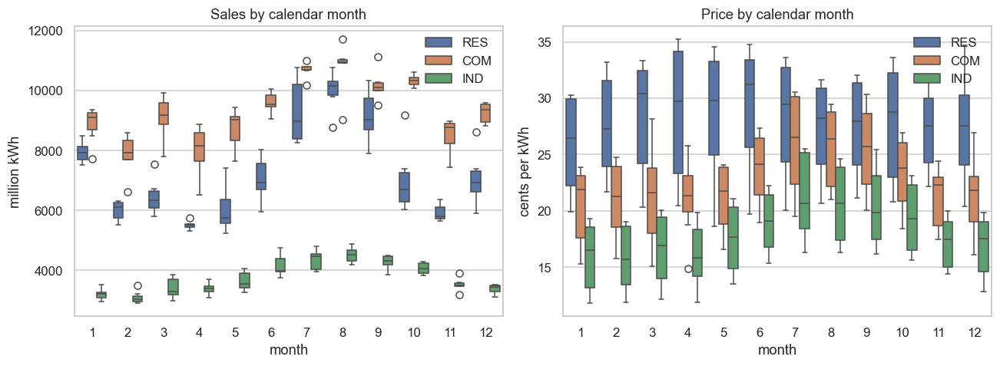

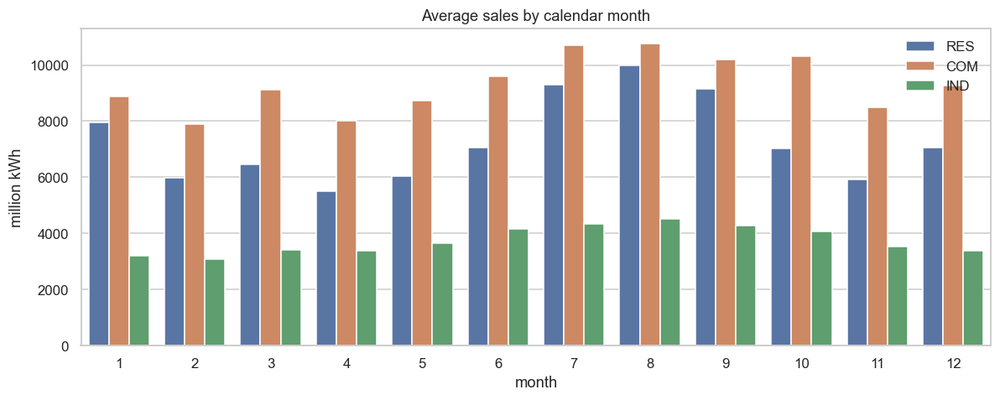

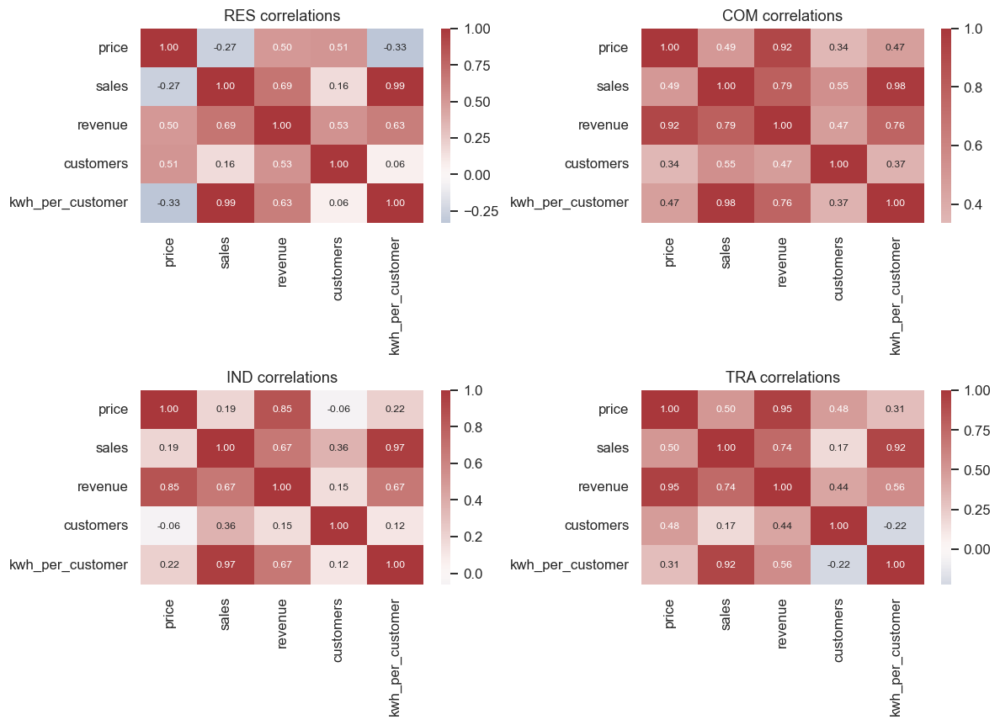

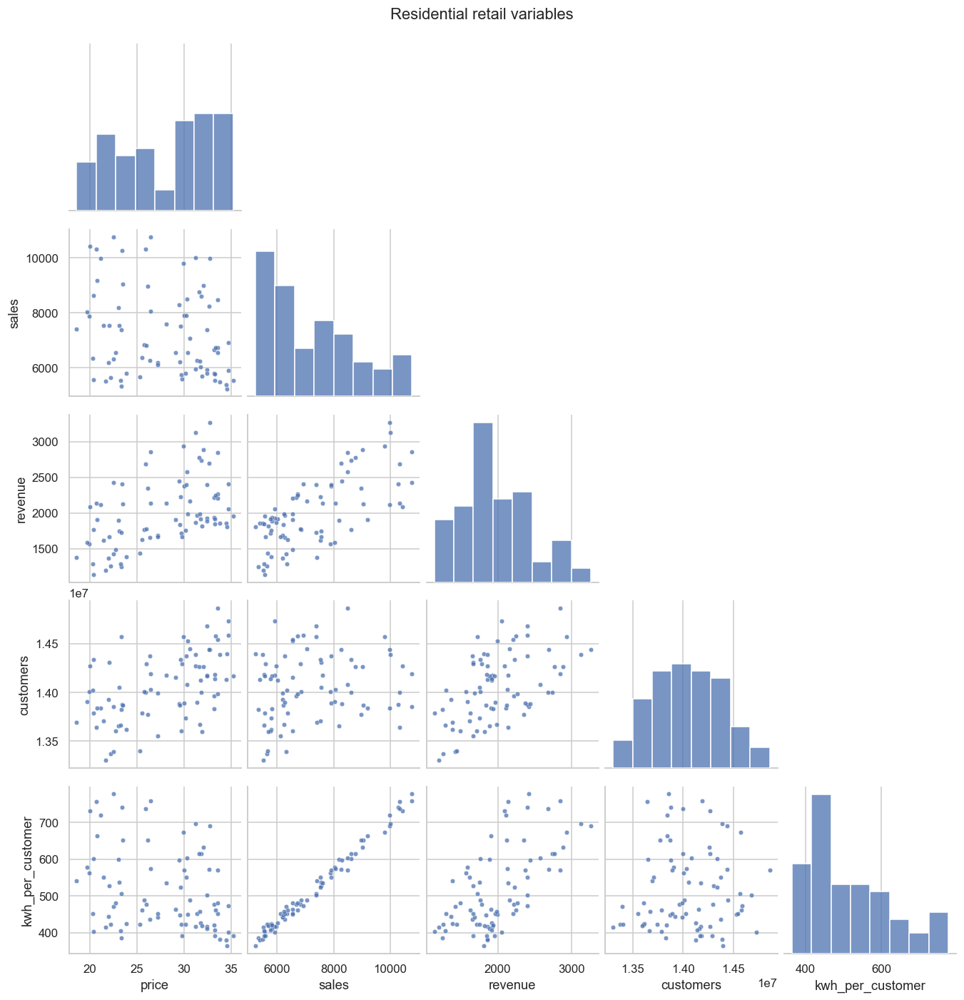

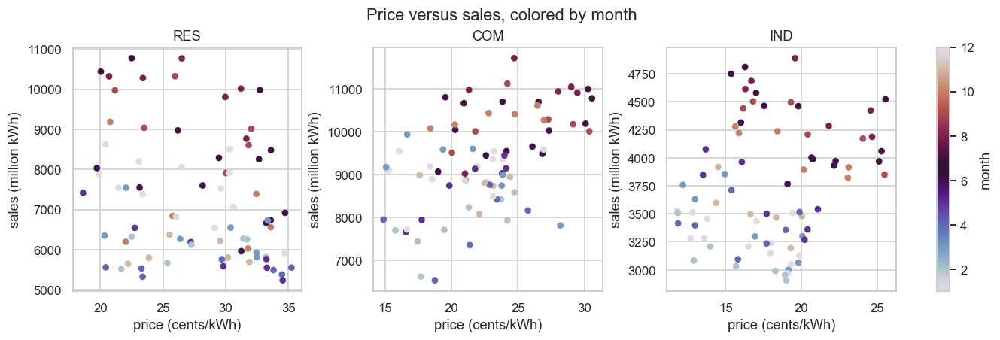

In [ ]:
season = eia[eia["sectorid"].isin(["RES", "COM", "IND"])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=season, x="month", y="sales", hue="sectorid", hue_order=["RES", "COM", "IND"], ax=axes[0])
axes[0].set_title("Sales by calendar month")
axes[0].set_ylabel("million kWh")
sns.boxplot(data=season, x="month", y="price", hue="sectorid", hue_order=["RES", "COM", "IND"], ax=axes[1])
axes[1].set_title("Price by calendar month")
axes[1].set_ylabel("cents per kWh")
for ax in axes:
    ax.legend(title=None, frameon=False)
fig.tight_layout()

month_means = (
    eia[eia["sectorid"].isin(["RES", "COM", "IND"])]
    .groupby(["month", "sectorid"], as_index=False)["sales"]
    .mean()
)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=month_means, x="month", y="sales", hue="sectorid", hue_order=["RES", "COM", "IND"], ax=ax)
ax.set_title("Average sales by calendar month")
ax.set_ylabel("million kWh")
ax.legend(title=None, frameon=False)
fig.tight_layout()

eia_cols = ["price", "sales", "revenue", "customers", "kwh_per_customer"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, sector in zip(axes.ravel(), ["RES", "COM", "IND", "TRA"]):
    corr = eia.loc[eia["sectorid"] == sector, eia_cols].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"{sector} correlations")
fig.tight_layout()

res = eia[eia["sectorid"] == "RES"]
grid = sns.pairplot(res[eia_cols], corner=True, diag_kind="hist", plot_kws={"s": 18, "alpha": 0.75})
grid.fig.suptitle("Residential retail variables", y=1.02)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, sector in zip(axes, ["RES", "COM", "IND"]):
    part = eia[eia["sectorid"] == sector]
    scatter = ax.scatter(part["price"], part["sales"], c=part["month"], cmap="twilight", s=22)
    ax.set_title(sector)
    ax.set_xlabel("price (cents/kWh)")
    ax.set_ylabel("sales (million kWh)")
fig.colorbar(scatter, ax=axes, label="month", fraction=0.03)
fig.suptitle("Price versus sales, colored by month")


## Weather, on its own

Daily points are the San Diego grid cell. Monthly series are what can line up with EIA. Radiation and sunshine move together, and so do mean temperature, CDD, and HDD. Those clusters matter later: they are one signal recorded several ways, not separate drivers.


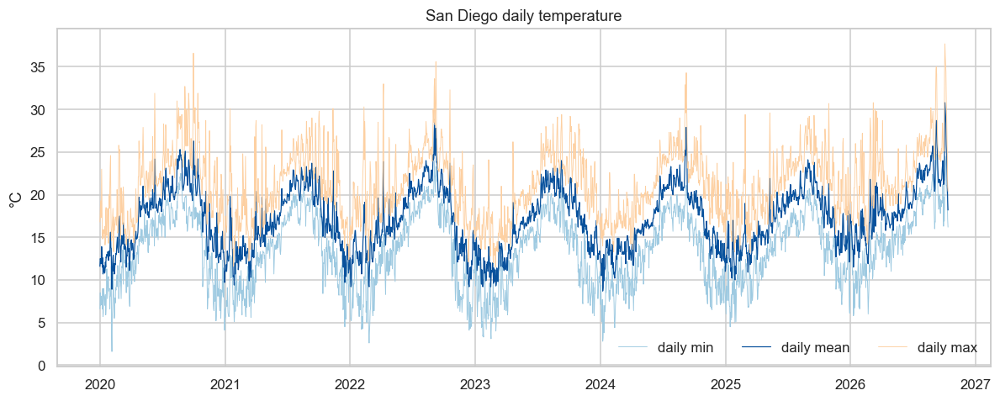

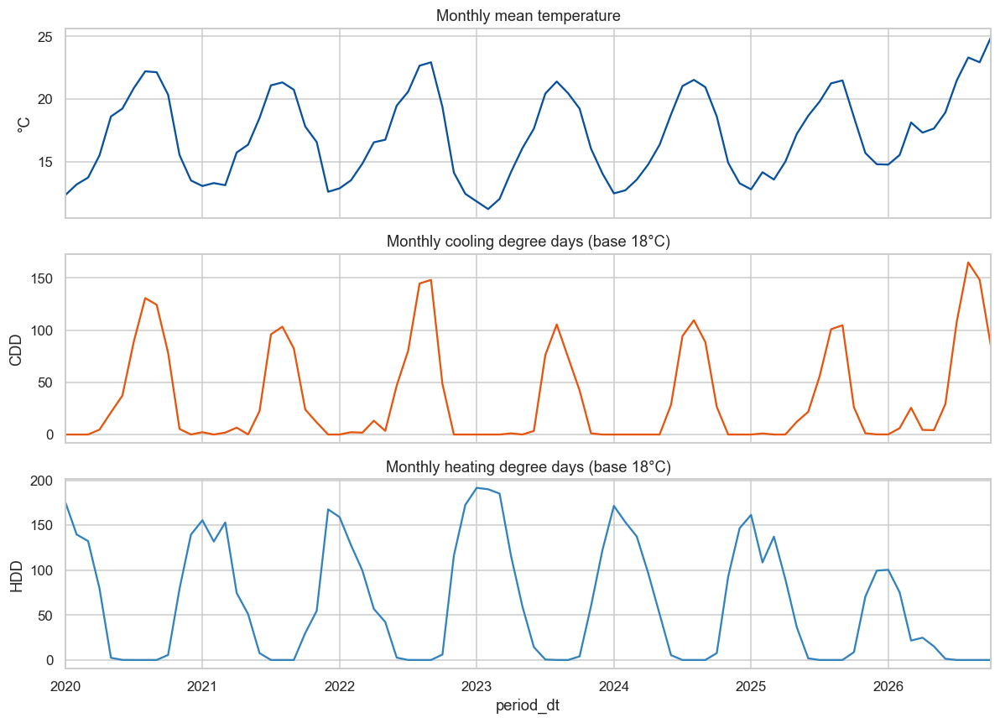

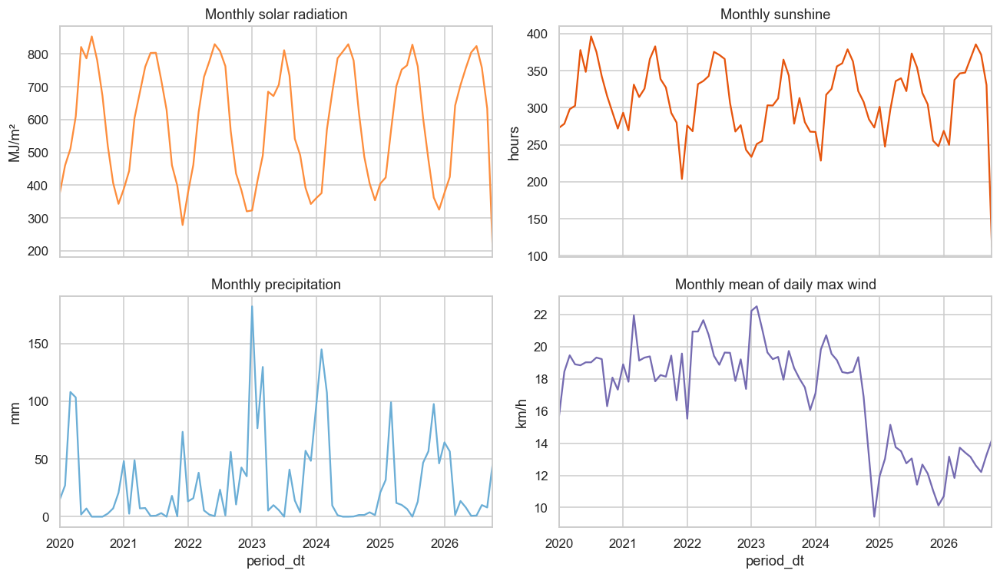

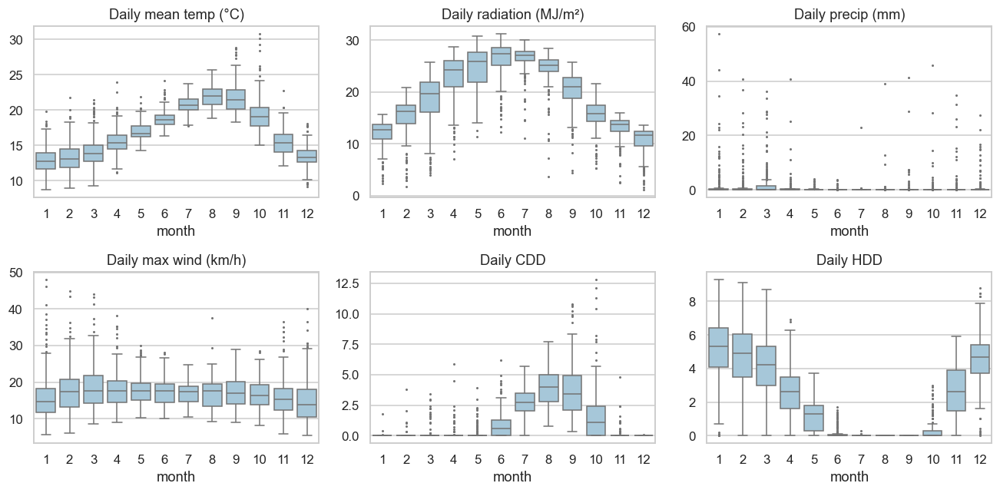

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily["time"], daily["temperature_2m_min"], color="#9ecae1", linewidth=0.6, label="daily min")
ax.plot(daily["time"], daily["temperature_2m_mean"], color="#08519c", linewidth=0.8, label="daily mean")
ax.plot(daily["time"], daily["temperature_2m_max"], color="#fdd0a2", linewidth=0.6, label="daily max")
ax.set_title("San Diego daily temperature")
ax.set_ylabel("°C")
ax.legend(ncol=3, frameon=False)
fig.tight_layout()

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
monthly_weather.set_index("period_dt")["temp_mean"].plot(ax=axes[0], color="#08519c", title="Monthly mean temperature")
axes[0].set_ylabel("°C")
monthly_weather.set_index("period_dt")["cdd"].plot(ax=axes[1], color="#e6550d", title="Monthly cooling degree days (base 18°C)")
axes[1].set_ylabel("CDD")
monthly_weather.set_index("period_dt")["hdd"].plot(ax=axes[2], color="#3182bd", title="Monthly heating degree days (base 18°C)")
axes[2].set_ylabel("HDD")
fig.tight_layout()

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
monthly_weather.set_index("period_dt")["radiation_mj"].plot(ax=axes[0, 0], title="Monthly solar radiation", color="#fd8d3c")
axes[0, 0].set_ylabel("MJ/m²")
monthly_weather.set_index("period_dt")["sunshine_hours"].plot(ax=axes[0, 1], title="Monthly sunshine", color="#e6550d")
axes[0, 1].set_ylabel("hours")
monthly_weather.set_index("period_dt")["precip_mm"].plot(ax=axes[1, 0], title="Monthly precipitation", color="#6baed6")
axes[1, 0].set_ylabel("mm")
monthly_weather.set_index("period_dt")["wind_mean"].plot(ax=axes[1, 1], title="Monthly mean of daily max wind", color="#756bb1")
axes[1, 1].set_ylabel("km/h")
fig.tight_layout()

weather_month_vars = [
    ("temperature_2m_mean", "Daily mean temp (°C)"),
    ("shortwave_radiation_sum", "Daily radiation (MJ/m²)"),
    ("precipitation_sum", "Daily precip (mm)"),
    ("wind_speed_10m_max", "Daily max wind (km/h)"),
    ("cdd", "Daily CDD"),
    ("hdd", "Daily HDD"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (column, label) in zip(axes.ravel(), weather_month_vars):
    sns.boxplot(data=daily, x="month", y=column, ax=ax, color="#9ecae1", fliersize=1)
    ax.set_title(label)
    ax.set_xlabel("month")
    ax.set_ylabel("")
fig.tight_layout()


Text(0.5, 1.02, 'Monthly weather pair plot')

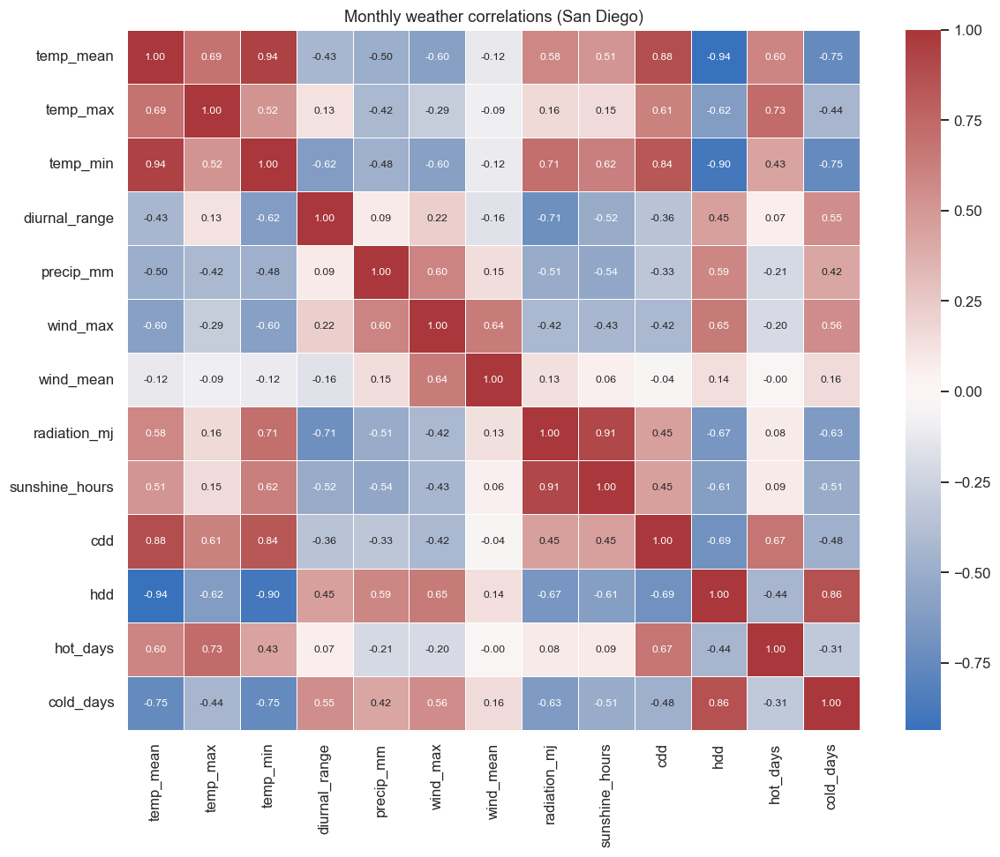

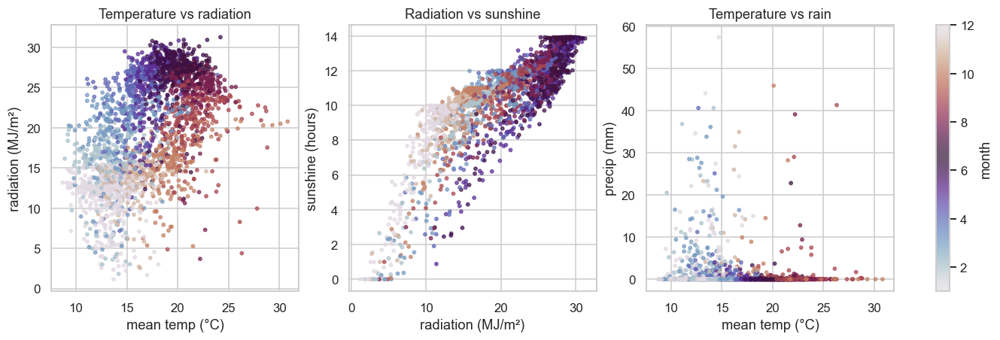

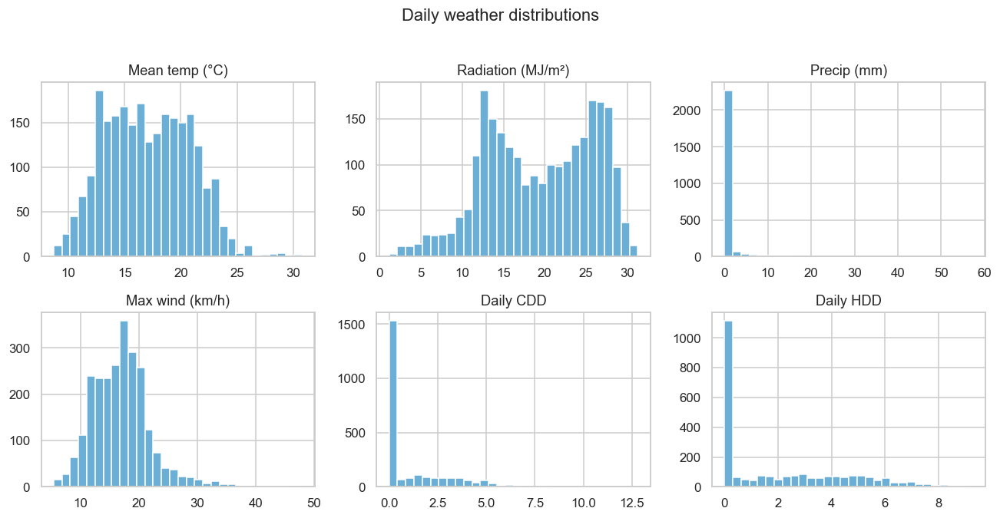

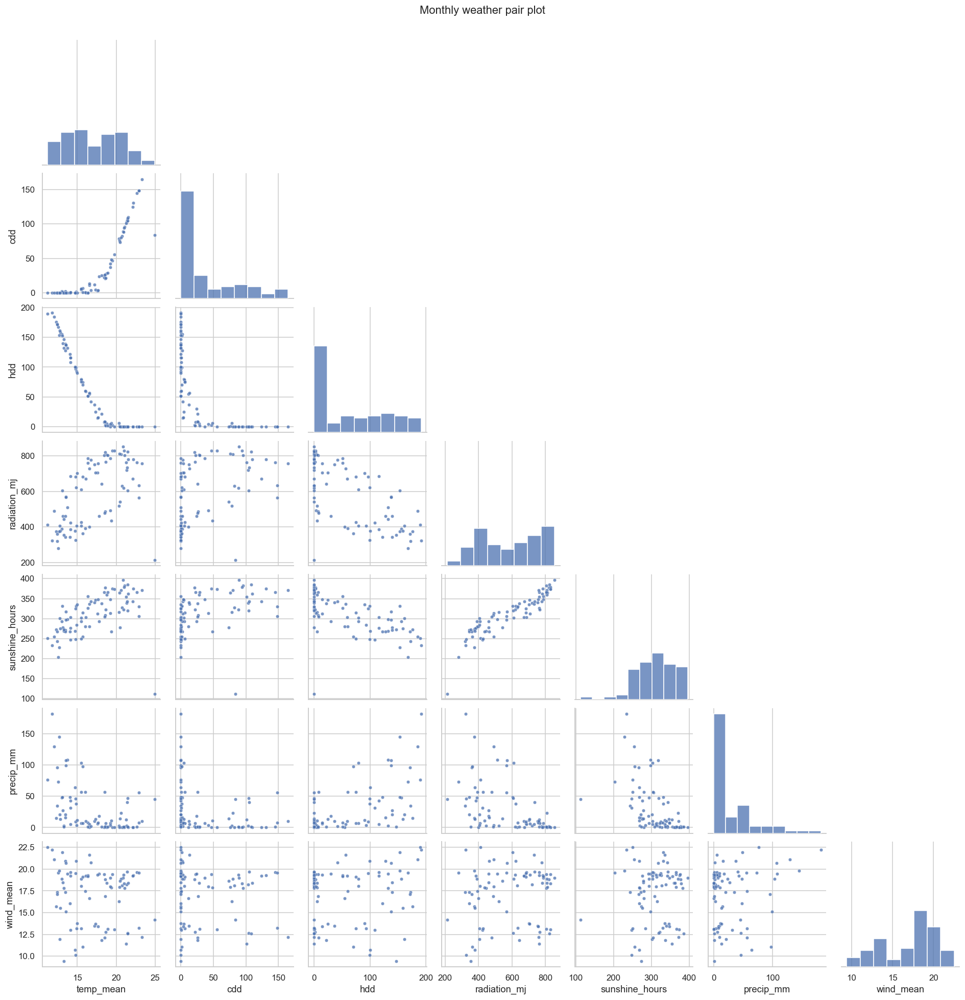

In [ ]:
heatmap(
    monthly_weather[WX].corr(),
    "Monthly weather correlations (San Diego)",
    figsize=(11, 9),
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
axes[0].scatter(daily["temperature_2m_mean"], daily["shortwave_radiation_sum"], c=daily["month"], cmap="twilight", s=8, alpha=0.7)
axes[0].set_xlabel("mean temp (°C)")
axes[0].set_ylabel("radiation (MJ/m²)")
axes[0].set_title("Temperature vs radiation")
axes[1].scatter(daily["shortwave_radiation_sum"], daily["sunshine_hours"], c=daily["month"], cmap="twilight", s=8, alpha=0.7)
axes[1].set_xlabel("radiation (MJ/m²)")
axes[1].set_ylabel("sunshine (hours)")
axes[1].set_title("Radiation vs sunshine")
scatter = axes[2].scatter(daily["temperature_2m_mean"], daily["precipitation_sum"], c=daily["month"], cmap="twilight", s=8, alpha=0.7)
axes[2].set_xlabel("mean temp (°C)")
axes[2].set_ylabel("precip (mm)")
axes[2].set_title("Temperature vs rain")
fig.colorbar(scatter, ax=axes, label="month", fraction=0.03)

hist_cols = [
    ("temperature_2m_mean", "Mean temp (°C)"),
    ("shortwave_radiation_sum", "Radiation (MJ/m²)"),
    ("precipitation_sum", "Precip (mm)"),
    ("wind_speed_10m_max", "Max wind (km/h)"),
    ("cdd", "Daily CDD"),
    ("hdd", "Daily HDD"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (column, label) in zip(axes.ravel(), hist_cols):
    ax.hist(daily[column], bins=30, color="#6baed6", edgecolor="white")
    ax.set_title(label)
fig.suptitle("Daily weather distributions", y=1.02)
fig.tight_layout()

grid = sns.pairplot(
    monthly_weather[["temp_mean", "cdd", "hdd", "radiation_mj", "sunshine_hours", "precip_mm", "wind_mean"]],
    corner=True,
    diag_kind="hist",
    plot_kws={"s": 18, "alpha": 0.75},
)
grid.fig.suptitle("Monthly weather pair plot", y=1.02)


## The two datasets together

EIA is monthly and statewide. Weather is aggregated to the same month, then merged on `period`. The first heatmaps are ordinary correlations, so a shared seasonal cycle counts as a relationship. The adjusted heatmap subtracts each variable's month-of-year average first. Whatever is still colored there is the part a model can use on top of a month effect.

`kWh per customer` is sales with the slow growth in customer counts taken out. For residential it tracks sales almost 1:1, because the customer base barely moves relative to the seasonal swing.


Sales vs weather


,temp_mean,temp_max,temp_min,diurnal_range,precip_mm,wind_max,wind_mean,radiation_mj,sunshine_hours,cdd,hdd,hot_days,cold_days
RES,0.63,0.35,0.61,-0.24,-0.19,-0.26,0.07,0.29,0.42,0.84,-0.40,0.43,-0.14
COM,0.66,0.25,0.62,-0.36,-0.16,-0.40,-0.04,0.33,0.41,0.70,-0.53,0.23,-0.36
IND,0.84,0.51,0.80,-0.46,-0.49,-0.37,0.25,0.60,0.67,0.80,-0.76,0.43,-0.55
TRA,0.21,-0.05,0.20,-0.14,-0.02,-0.23,-0.15,0.04,-0.03,0.20,-0.18,0.00,-0.21
ALL,0.75,0.38,0.72,-0.35,-0.26,-0.36,0.07,0.40,0.51,0.88,-0.57,0.40,-0.32


Sales vs weather, month-of-year average removed


,temp_mean,temp_max,temp_min,diurnal_range,precip_mm,wind_max,wind_mean,radiation_mj,sunshine_hours,cdd,hdd,hot_days,cold_days
RES,0.27,0.24,0.19,0.06,-0.06,0.07,0.24,0.25,0.26,0.59,-0.03,0.30,0.08
COM,-0.13,-0.18,-0.13,-0.17,0.23,-0.09,-0.04,-0.25,-0.18,-0.03,0.16,-0.33,-0.02
IND,0.12,0.28,-0.05,0.07,-0.24,0.22,0.49,0.26,0.28,0.31,0.02,0.20,0.10
TRA,-0.17,-0.36,-0.06,-0.11,0.06,-0.20,-0.22,-0.33,-0.36,-0.26,0.07,-0.33,-0.10
ALL,0.14,0.13,0.04,-0.04,0.03,0.05,0.26,0.09,0.14,0.46,0.07,0.07,0.07


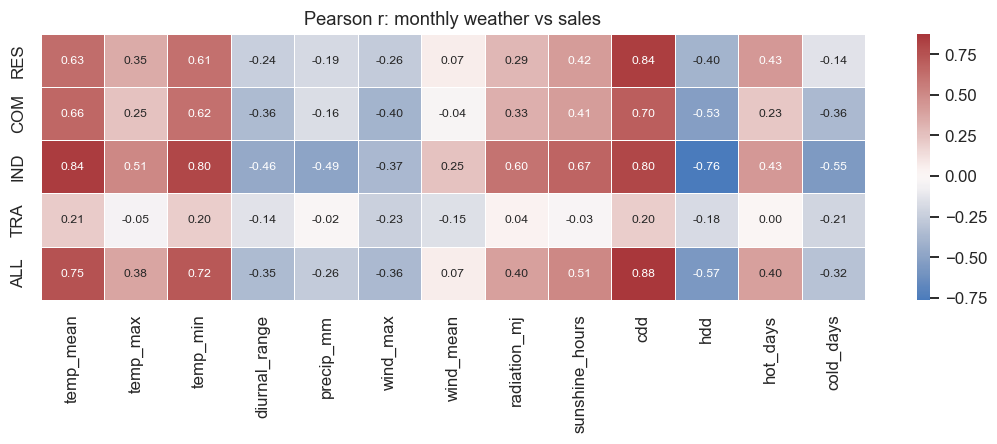

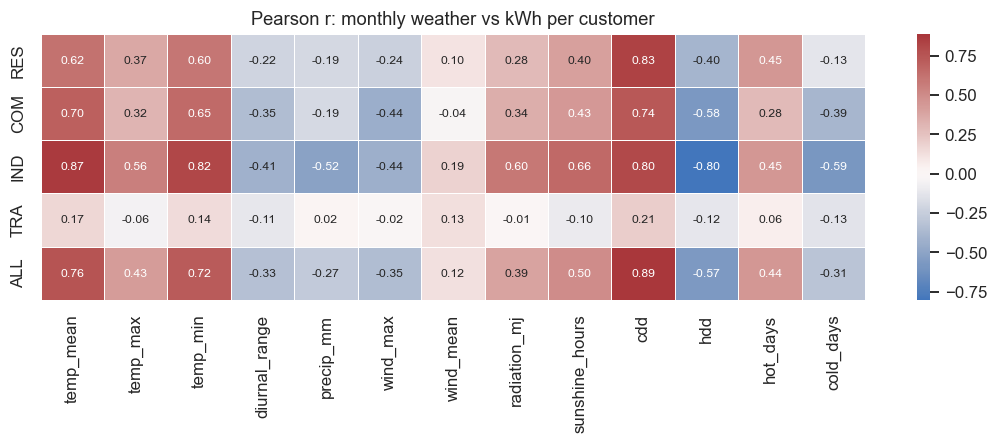

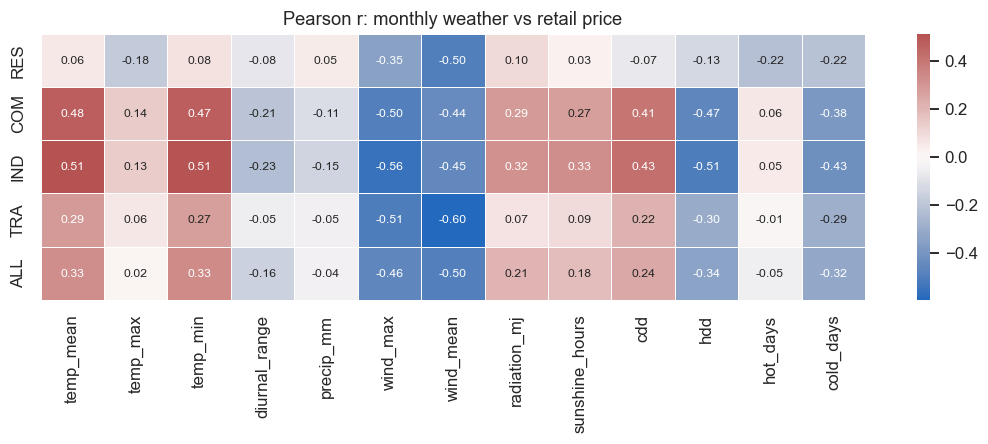

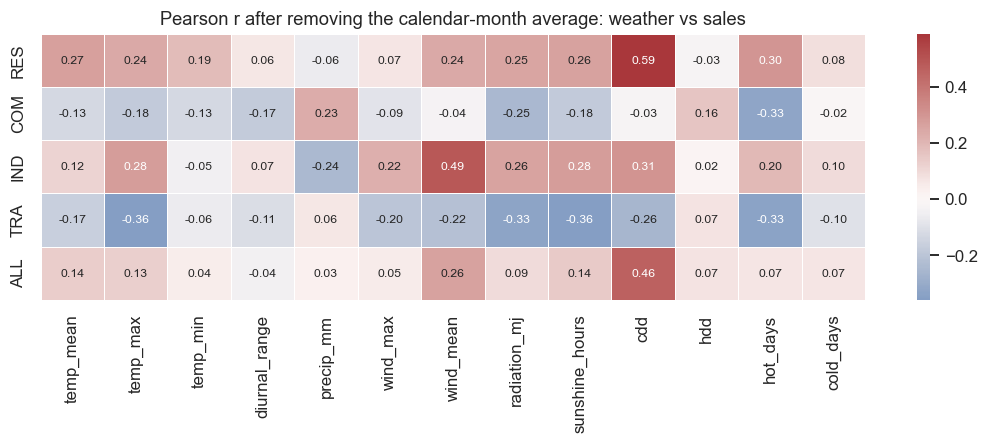

In [ ]:
sales_corr = cross_corr(panel, "sales")
kwh_corr = cross_corr(panel, "kwh_per_customer")
price_corr = cross_corr(panel, "price")
sales_adj = month_adjusted_corr(panel, "sales")

heatmap(sales_corr, "Pearson r: monthly weather vs sales")
heatmap(kwh_corr, "Pearson r: monthly weather vs kWh per customer")
heatmap(price_corr, "Pearson r: monthly weather vs retail price")
heatmap(sales_adj, "Pearson r after removing the calendar-month average: weather vs sales")

print("Sales vs weather")
display(sales_corr.round(2))
print("Sales vs weather, month-of-year average removed")
display(sales_adj.round(2))


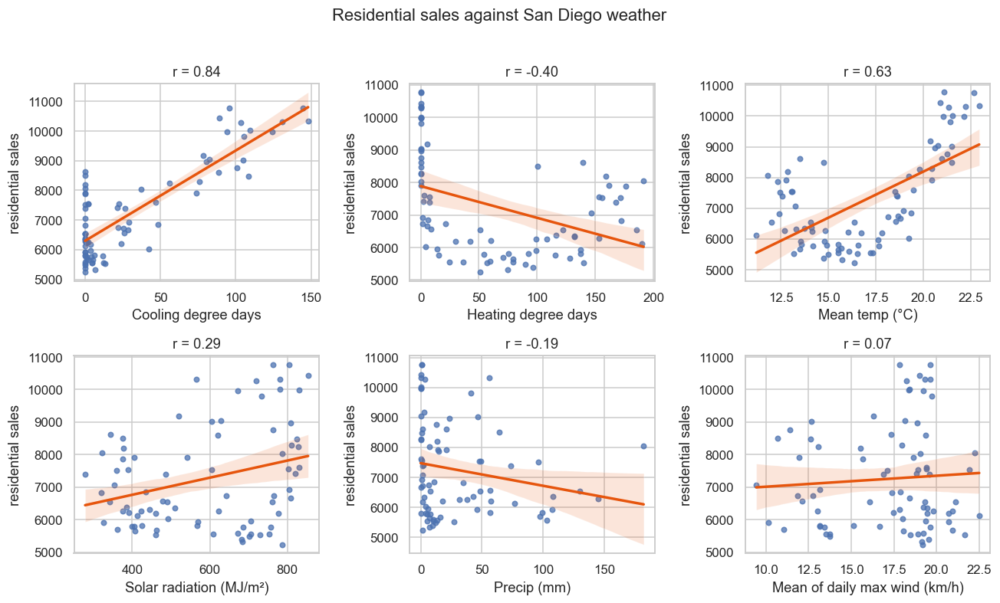

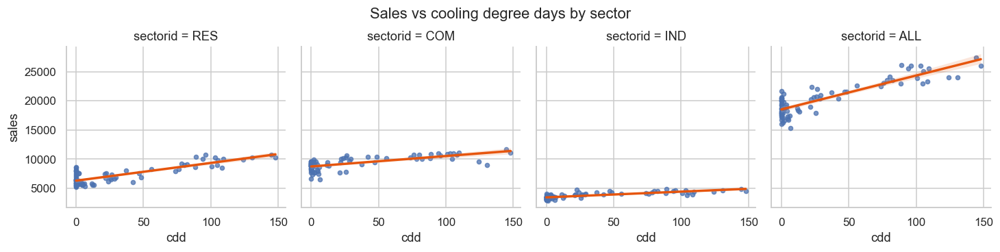

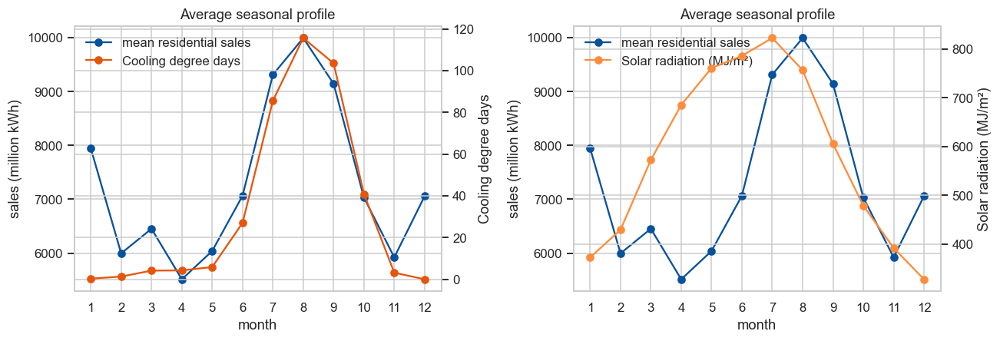

In [ ]:
res = panel[panel["sectorid"] == "RES"].sort_values("period_dt")
features = ["cdd", "hdd", "temp_mean", "radiation_mj", "precip_mm", "wind_mean"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, feature in zip(axes.ravel(), features):
    sns.regplot(data=res, x=feature, y="sales", ax=ax, scatter_kws={"s": 18, "alpha": 0.75}, line_kws={"color": "#e6550d"})
    r = res["sales"].corr(res[feature])
    ax.set_title(f"r = {r:.2f}")
    ax.set_xlabel(WX_LABELS[feature])
    ax.set_ylabel("residential sales")
fig.suptitle("Residential sales against San Diego weather", y=1.02)
fig.tight_layout()

sns.lmplot(
    data=panel[panel["sectorid"].isin(MAIN_SECTORS)],
    x="cdd",
    y="sales",
    col="sectorid",
    col_order=MAIN_SECTORS,
    height=3.2,
    aspect=1.05,
    scatter_kws={"s": 16, "alpha": 0.75},
    line_kws={"color": "#e6550d"},
).fig.suptitle("Sales vs cooling degree days by sector", y=1.04)

profile = res.groupby("month").agg(
    sales=("sales", "mean"),
    cdd=("cdd", "mean"),
    hdd=("hdd", "mean"),
    temp_mean=("temp_mean", "mean"),
    radiation_mj=("radiation_mj", "mean"),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, feature, color in (
    (axes[0], "cdd", "#e6550d"),
    (axes[1], "radiation_mj", "#fd8d3c"),
):
    ax.plot(profile.index, profile["sales"], color="#08519c", marker="o", label="mean residential sales")
    twin = ax.twinx()
    twin.plot(profile.index, profile[feature], color=color, marker="o", label=WX_LABELS[feature])
    ax.set_xlabel("month")
    ax.set_ylabel("sales (million kWh)")
    twin.set_ylabel(WX_LABELS[feature])
    ax.set_xticks(range(1, 13))
    ax.set_title("Average seasonal profile")
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = twin.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, frameon=False, loc="upper left")
fig.tight_layout()


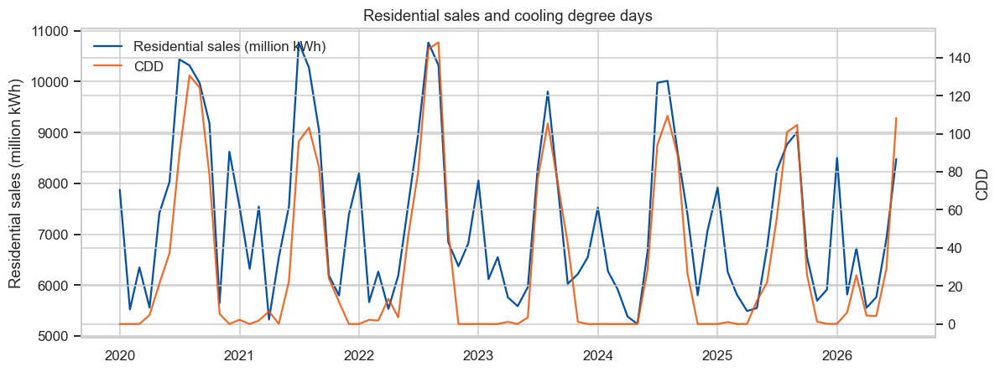

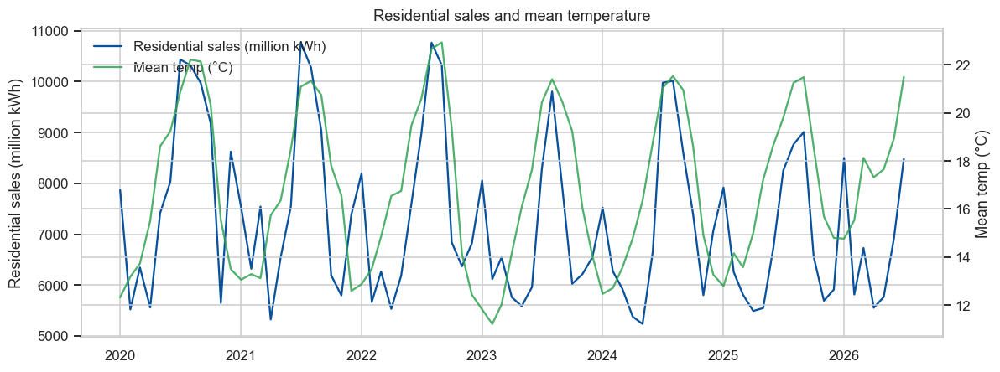

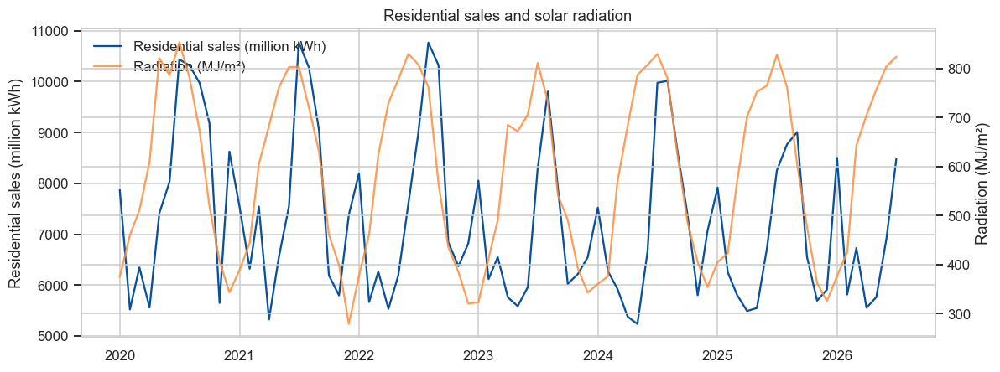

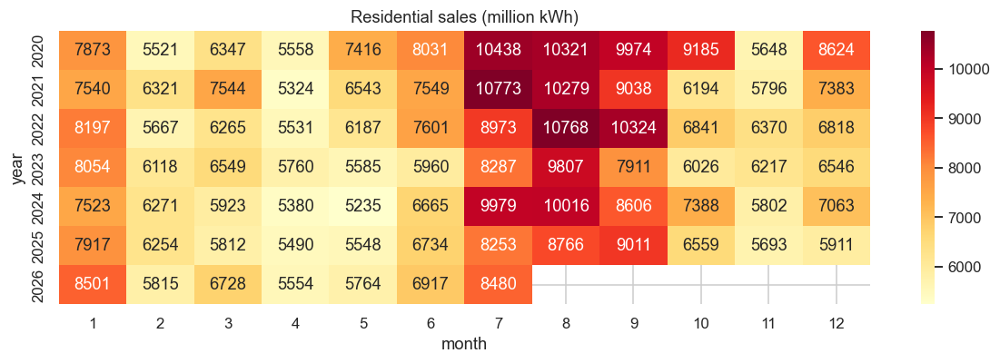

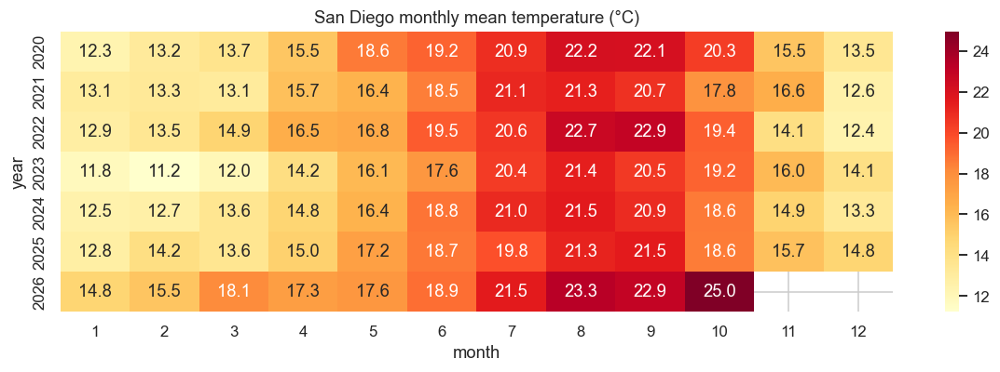

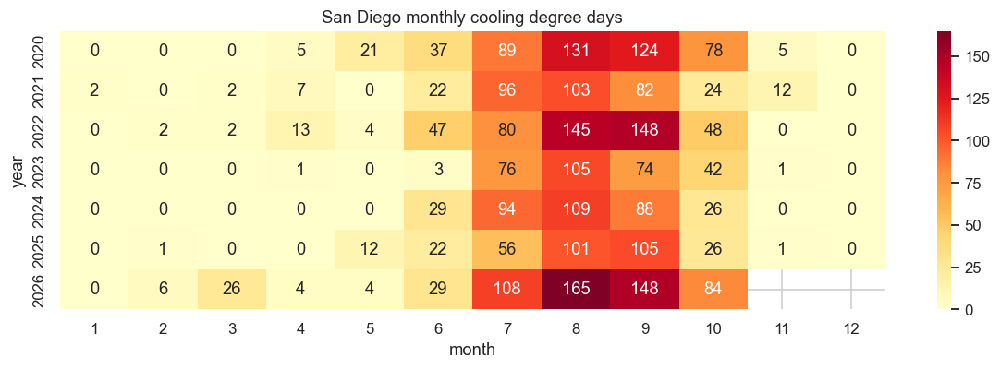

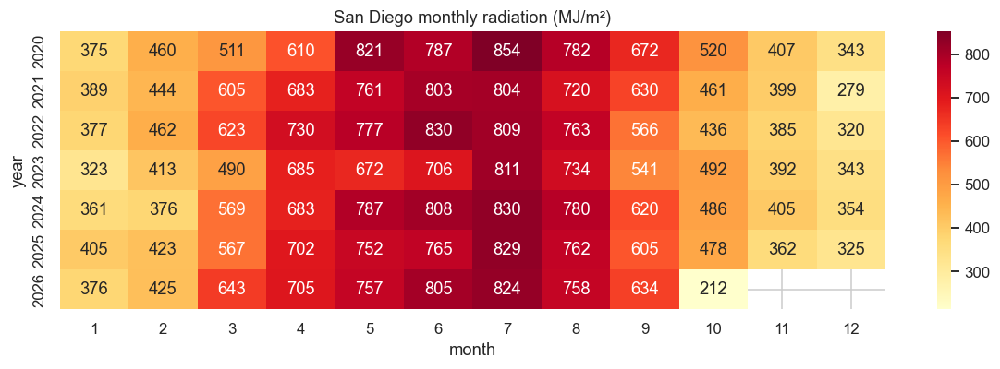

In [ ]:
res = panel[panel["sectorid"] == "RES"].sort_values("period_dt")

def twin_series(frame, left, right, left_label, right_label, title, right_color):
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.plot(frame["period_dt"], frame[left], color="#08519c", label=left_label)
    twin = ax.twinx()
    twin.plot(frame["period_dt"], frame[right], color=right_color, alpha=0.85, label=right_label)
    ax.set_ylabel(left_label)
    twin.set_ylabel(right_label)
    ax.set_title(title)
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = twin.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, frameon=False, loc="upper left")
    fig.tight_layout()

twin_series(res, "sales", "cdd", "Residential sales (million kWh)", "CDD", "Residential sales and cooling degree days", "#e6550d")
twin_series(res, "sales", "temp_mean", "Residential sales (million kWh)", "Mean temp (°C)", "Residential sales and mean temperature", "#31a354")
twin_series(res, "sales", "radiation_mj", "Residential sales (million kWh)", "Radiation (MJ/m²)", "Residential sales and solar radiation", "#fd8d3c")

def calendar(frame, value, title, fmt):
    pivot = frame.pivot(index="year", columns="month", values=value)
    fig, ax = plt.subplots(figsize=(11, 3.8))
    sns.heatmap(pivot, annot=True, fmt=fmt, cmap="YlOrRd", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("month")
    fig.tight_layout()

calendar(res, "sales", "Residential sales (million kWh)", ".0f")
calendar(monthly_weather, "temp_mean", "San Diego monthly mean temperature (°C)", ".1f")
calendar(monthly_weather, "cdd", "San Diego monthly cooling degree days", ".0f")
calendar(monthly_weather, "radiation_mj", "San Diego monthly radiation (MJ/m²)", ".0f")


Residential sales vs CDD, linear time trend removed: r = 0.84


Text(0.5, 1.02, 'Residential month: sales, price, and the weather features worth comparing')

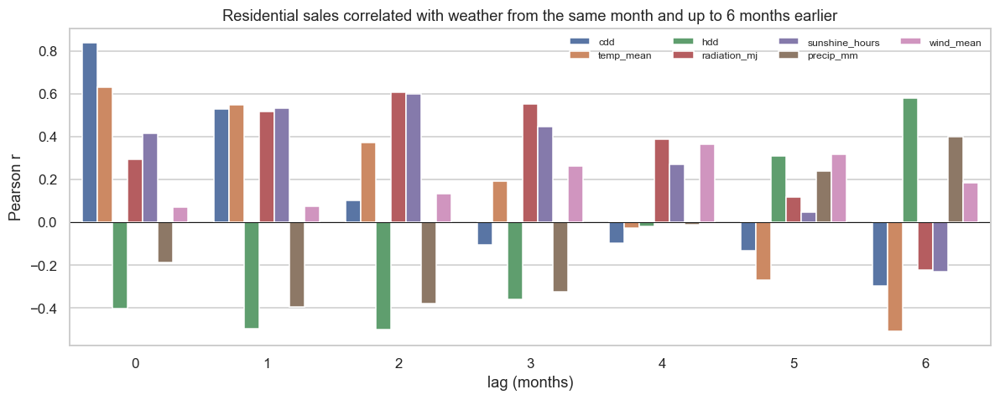

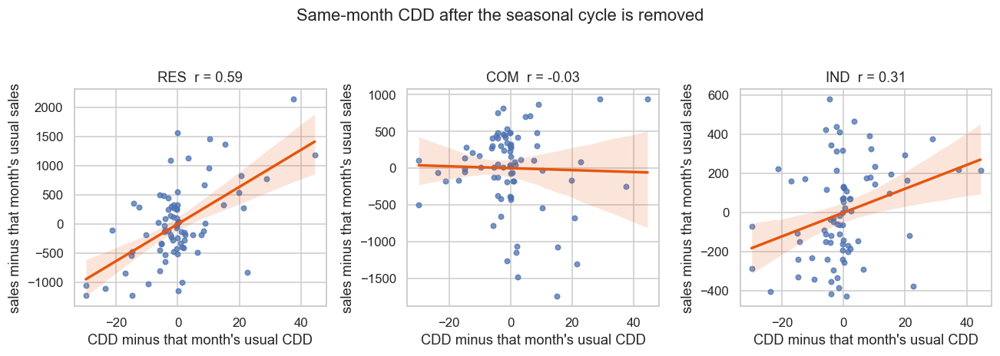

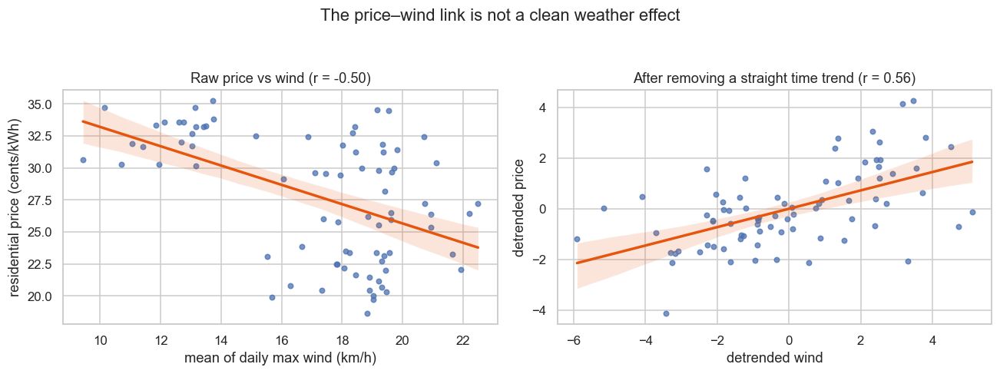

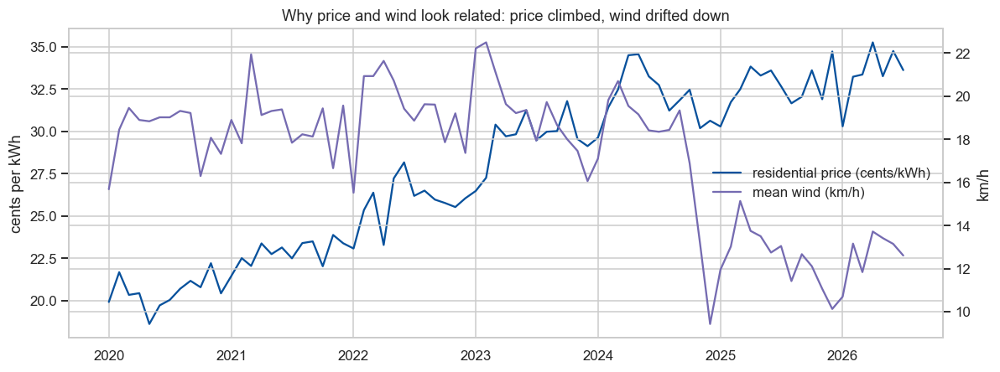

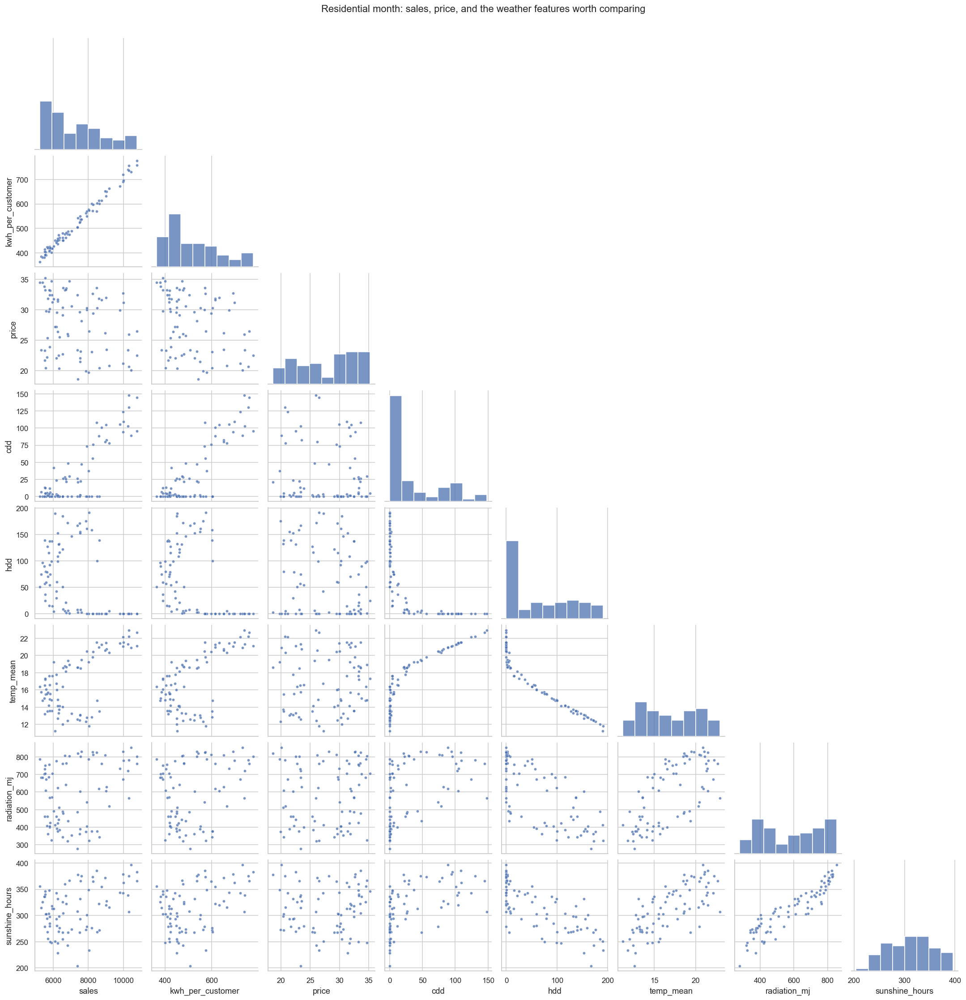

In [ ]:
res = panel[panel["sectorid"] == "RES"].sort_values("period_dt").copy()
lag_features = ["cdd", "temp_mean", "hdd", "radiation_mj", "sunshine_hours", "precip_mm", "wind_mean"]
lag_rows = []
for feature in lag_features:
    for lag in range(0, 7):
        lag_rows.append({"feature": feature, "lag_months": lag, "r": res["sales"].corr(res[feature].shift(lag))})
lags = pd.DataFrame(lag_rows)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=lags, x="lag_months", y="r", hue="feature", ax=ax)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("Residential sales correlated with weather from the same month and up to 6 months earlier")
ax.set_ylabel("Pearson r")
ax.set_xlabel("lag (months)")
ax.legend(ncol=4, frameon=False, fontsize=8)
fig.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=False)
for ax, sector in zip(axes, ["RES", "COM", "IND"]):
    group = panel[panel["sectorid"] == sector].copy()
    for column in ("sales", "cdd"):
        group[column] = group[column] - group.groupby("month")[column].transform("mean")
    sns.regplot(data=group, x="cdd", y="sales", ax=ax, scatter_kws={"s": 18, "alpha": 0.75}, line_kws={"color": "#e6550d"})
    r = group["sales"].corr(group["cdd"])
    ax.set_title(f"{sector}  r = {r:.2f}")
    ax.set_xlabel("CDD minus that month's usual CDD")
    ax.set_ylabel("sales minus that month's usual sales")
fig.suptitle("Same-month CDD after the seasonal cycle is removed", y=1.05)
fig.tight_layout()

# Price rose almost in a straight line. Mean wind drifted down. The raw price–wind
# correlation is mostly those two trends.
res["t"] = np.arange(len(res))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
raw_r = res["price"].corr(res["wind_mean"])
sns.regplot(data=res, x="wind_mean", y="price", ax=axes[0], scatter_kws={"s": 18, "alpha": 0.75}, line_kws={"color": "#e6550d"})
axes[0].set_title(f"Raw price vs wind (r = {raw_r:.2f})")
axes[0].set_xlabel("mean of daily max wind (km/h)")
axes[0].set_ylabel("residential price (cents/kWh)")

detrended = res.copy()
for column in ("price", "wind_mean", "sales", "cdd"):
    slope, intercept = np.polyfit(detrended["t"], detrended[column], 1)
    detrended[column] = detrended[column] - (slope * detrended["t"] + intercept)
detrended_r = detrended["price"].corr(detrended["wind_mean"])
cdd_r = detrended["sales"].corr(detrended["cdd"])
sns.regplot(data=detrended, x="wind_mean", y="price", ax=axes[1], scatter_kws={"s": 18, "alpha": 0.75}, line_kws={"color": "#e6550d"})
axes[1].set_title(f"After removing a straight time trend (r = {detrended_r:.2f})")
axes[1].set_xlabel("detrended wind")
axes[1].set_ylabel("detrended price")
fig.suptitle("The price–wind link is not a clean weather effect", y=1.05)
fig.tight_layout()
print(f"Residential sales vs CDD, linear time trend removed: r = {cdd_r:.2f}")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(res["period_dt"], res["price"], color="#08519c", label="residential price (cents/kWh)")
twin = ax.twinx()
twin.plot(res["period_dt"], res["wind_mean"], color="#756bb1", label="mean wind (km/h)")
ax.set_title("Why price and wind look related: price climbed, wind drifted down")
ax.set_ylabel("cents per kWh")
twin.set_ylabel("km/h")
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = twin.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, frameon=False, loc="center right")
fig.tight_layout()

joined = res[["sales", "kwh_per_customer", "price", "cdd", "hdd", "temp_mean", "radiation_mj", "sunshine_hours"]]
grid = sns.pairplot(joined, corner=True, diag_kind="hist", plot_kws={"s": 16, "alpha": 0.75})
grid.fig.suptitle("Residential month: sales, price, and the weather features worth comparing", y=1.02)


## What is worth putting in a model

Numbers below are Pearson correlations on the California × San Diego monthly panel, January 2020 through July 2026 (79 months).

**Target.** Residential `sales` (million kWh). `kwh_per_customer` is almost the same series (r = 0.99 with sales) and is the one to use if you want customer growth out of the target. Commercial and industrial sales are usable second targets. Skip `OTH` (every value is 0). Transportation is about 56 million kWh a month and barely follows this weather.

**Use these**

- **Calendar month.** Residential sales peak in August (about 10,000 million kWh), bottom out in April (about 5,500), and have a smaller winter bump in December–January (about 7,000–7,900). A month feature is the baseline.
- **Same-month CDD.** Strongest weather feature. Residential r = 0.84, all-sectors 0.88, industrial 0.80, commercial 0.70. It still holds after a straight time trend is removed (residential r stays about 0.84) and after the calendar-month average is removed (residential r = 0.59, all-sectors 0.46, industrial 0.31). Commercial drops to about 0. The heat signal on top of season is a residential story.
- **Mean temperature, as a substitute for CDD, not a second feature.** Residential sales r = 0.63. Temperature and CDD move together (r = 0.88).

**Optional, and only one of them**

- **Sunshine hours or radiation.** They are the same solar signal (r = 0.91). Raw link to residential sales is moderate (sunshine 0.42, radiation 0.29). After removing the calendar month, both are about 0.25. Radiation's correlation is higher at a 2-month lag (r = 0.60) than in the same month (r = 0.29) because the sun peaks in June–July and residential sales peak in August. CDD already peaks with sales in August, so the lag is the seasonal offset, not a reason to delay the solar feature.

**Leave out of the first model**

- **HDD as an extra residual feature.** Raw residential r = −0.40, which is the winter. After the calendar month is removed, r is about 0. Mean temperature and HDD are nearly mirrors (r = −0.94).
- **Precipitation and wind as sales features.** Weak for residential sales. Industrial sales do show a residual link with mean wind (about 0.49 after the month average is removed). That is large enough to plot and too shaky to trust until it shows up with a statewide weather series.
- **Retail price as a weather outcome.** Residential price vs mean temperature is r = 0.06. Price vs time is r = 0.95: it climbed in a nearly straight line. Wind drifted down over the same years (r = −0.66 with time), which is why price and wind look related in the raw scatter. Price is a tariff series.
- **Stacking temperature, CDD, HDD, radiation, and sunshine in one linear model.** They repeat the same seasonal cycle. The model will split one signal across collinear columns.
- **`ALL` as a feature next to the sectors.** It is their total.

**A reasonable first specification.** Residential sales ~ month + CDD. Then try adding sunshine hours and see whether the error actually drops. Hold out a later year (2025 or 2026) rather than random months, because neighboring months are not independent.

**Geography.** This CDD is one coastal grid cell and the sales are all of California. The match is already strong, which is why it is good enough to start. Inland heat will not show up fully in the San Diego series. A Sacramento or Central Valley Open-Meteo pull is the check if the residual in summer still looks large.


In [ ]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

SECTORS = ["RES", "COM", "IND", "TRA", "OTH", "ALL"]
MAIN_SECTORS = ["RES", "COM", "IND", "ALL"]
COMPARE_SECTORS = ["RES", "COM", "IND", "TRA", "ALL"]
SECTOR_COLORS = dict(zip(SECTORS, sns.color_palette("tab10", n_colors=len(SECTORS))))

WX = [
    "temp_mean",
    "temp_max",
    "temp_min",
    "diurnal_range",
    "precip_mm",
    "wind_max",
    "wind_mean",
    "radiation_mj",
    "sunshine_hours",
    "cdd",
    "hdd",
    "hot_days",
    "cold_days",
]
WX_LABELS = {
    "temp_mean": "Mean temp (°C)",
    "temp_max": "Max temp (°C)",
    "temp_min": "Min temp (°C)",
    "diurnal_range": "Diurnal range (°C)",
    "precip_mm": "Precip (mm)",
    "wind_max": "Max wind (km/h)",
    "wind_mean": "Mean of daily max wind (km/h)",
    "radiation_mj": "Solar radiation (MJ/m²)",
    "sunshine_hours": "Sunshine (hours)",
    "cdd": "Cooling degree days",
    "hdd": "Heating degree days",
    "hot_days": "Days ≥ 28°C",
    "cold_days": "Days with min ≤ 8°C",
}

eia = eia_retail_sales.copy()
eia["period_dt"] = pd.to_datetime(eia["period"])
eia["year"] = eia["period_dt"].dt.year
eia["month"] = eia["period_dt"].dt.month
eia["kwh_per_customer"] = np.where(
    eia["customers"] > 0,
    eia["sales"] * 1_000_000 / eia["customers"],
    np.nan,
)

daily = weather.copy()
daily["cdd"] = (daily["temperature_2m_mean"] - 18).clip(lower=0)
daily["hdd"] = (18 - daily["temperature_2m_mean"]).clip(lower=0)
daily["diurnal_range"] = daily["temperature_2m_max"] - daily["temperature_2m_min"]
daily["sunshine_hours"] = daily["sunshine_duration"] / 3600
daily["period"] = daily["time"].dt.strftime("%Y-%m")
daily["month"] = daily["time"].dt.month
daily["year"] = daily["time"].dt.year

monthly_weather = daily.groupby("period", as_index=False).agg(
    temp_mean=("temperature_2m_mean", "mean"),
    temp_max=("temperature_2m_max", "max"),
    temp_min=("temperature_2m_min", "min"),
    diurnal_range=("diurnal_range", "mean"),
    precip_mm=("precipitation_sum", "sum"),
    wind_max=("wind_speed_10m_max", "max"),
    wind_mean=("wind_speed_10m_max", "mean"),
    radiation_mj=("shortwave_radiation_sum", "sum"),
    sunshine_hours=("sunshine_hours", "sum"),
    cdd=("cdd", "sum"),
    hdd=("hdd", "sum"),
    hot_days=("temperature_2m_max", lambda s: int((s >= 28).sum())),
    cold_days=("temperature_2m_min", lambda s: int((s <= 8).sum())),
)
monthly_weather["period_dt"] = pd.to_datetime(monthly_weather["period"])
monthly_weather["month"] = monthly_weather["period_dt"].dt.month
monthly_weather["year"] = monthly_weather["period_dt"].dt.year

panel = eia.merge(
    monthly_weather.drop(columns=["period_dt", "month", "year"]),
    on="period",
    how="inner",
)
print(f"panel {panel.shape[0]} rows, {panel['period'].min()} to {panel['period'].max()}")
print(f"daily weather {daily.shape[0]} days, monthly weather {monthly_weather.shape[0]} months")


def small_multiples(frame, y, title, ylabel, sectors=SECTORS, logy=False):
    ncols = 3 if len(sectors) > 3 else len(sectors)
    nrows = int(np.ceil(len(sectors) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.1 * nrows), sharex=True, squeeze=False)
    flat = axes.ravel()
    for ax, sector in zip(flat, sectors):
        part = frame[frame["sectorid"] == sector].sort_values("period_dt")
        ax.plot(part["period_dt"], part[y], color=SECTOR_COLORS[sector], linewidth=1.5)
        ax.set_title(sector)
        if logy:
            ax.set_yscale("log")
        ax.tick_params(axis="x", labelrotation=30)
        if part[y].nunique(dropna=True) <= 1:
            ax.set_ylim(-1, 1)
    for ax in flat[len(sectors):]:
        ax.set_visible(False)
    fig.suptitle(title, y=1.02)
    fig.supylabel(ylabel)
    fig.tight_layout()


def heatmap(frame, title, figsize=(10, 4.2), fmt=".2f"):
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        frame,
        annot=True,
        fmt=fmt,
        cmap="vlag",
        center=0,
        linewidths=0.4,
        ax=ax,
        annot_kws={"size": 8},
    )
    ax.set_title(title)
    fig.tight_layout()


def cross_corr(frame, target, method="pearson"):
    rows = {}
    for sector, group in frame.groupby("sectorid"):
        if sector == "OTH" or group[target].std(skipna=True) == 0:
            continue
        rows[sector] = group[WX + [target]].corr(method=method)[target].drop(target)
    return pd.DataFrame(rows).T.reindex(COMPARE_SECTORS)


def month_adjusted_corr(frame, target):
    rows = {}
    for sector, group in frame.groupby("sectorid"):
        if sector == "OTH":
            continue
        group = group.copy()
        columns = WX + [target]
        for column in columns:
            group[column] = group[column] - group.groupby("month")[column].transform("mean")
        if group[target].std(skipna=True) == 0:
            continue
        rows[sector] = group[columns].corr()[target].drop(target)
    return pd.DataFrame(rows).T.reindex(COMPARE_SECTORS)


panel 474 rows, 2020-01 to 2026-07
daily weather 2477 days, monthly weather 82 months


## EIA, on its own

Each sector gets its own y-axis so transportation and the empty `OTH` series do not flatten the others. The index chart then puts RES, COM, IND, and ALL on one scale (value divided by that sector's own mean) so the seasonal shapes can be compared.


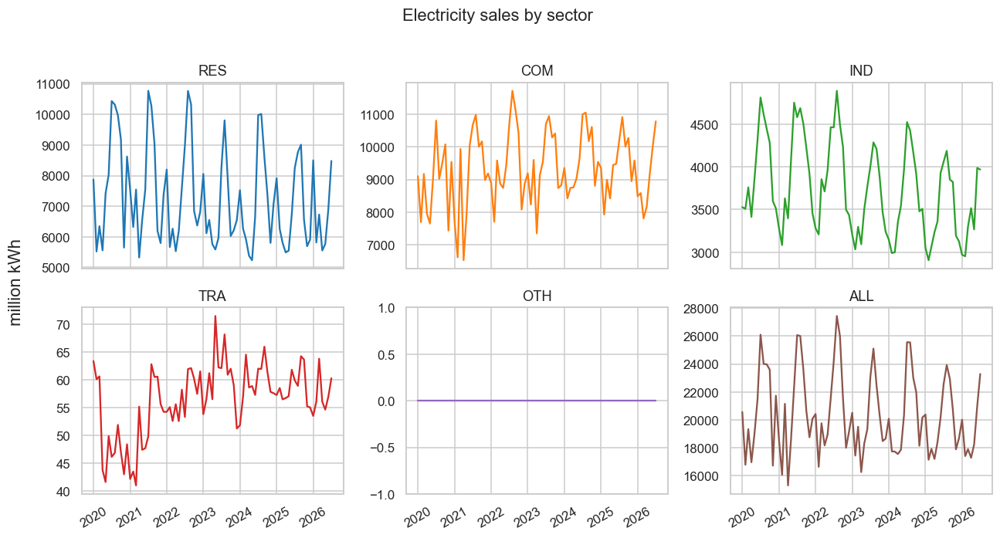

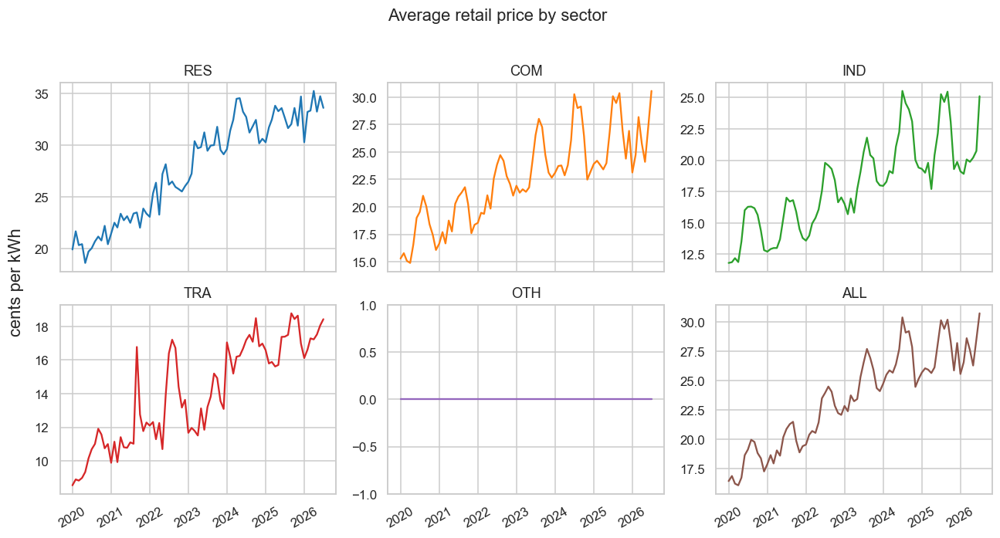

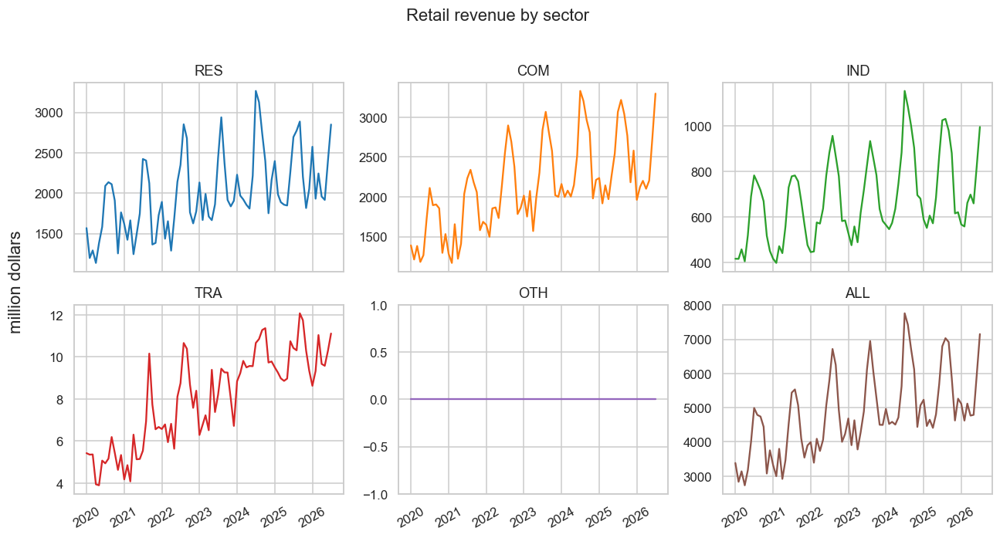

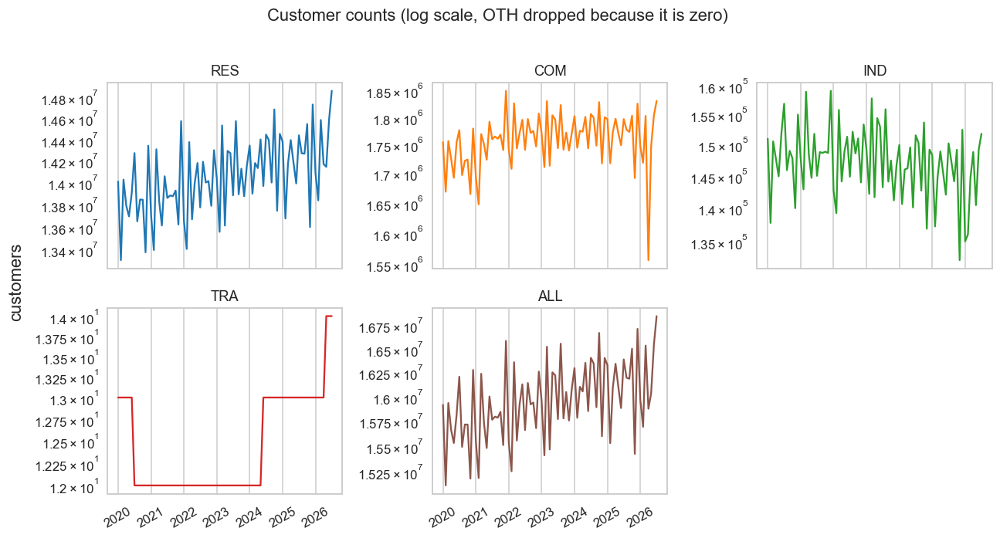

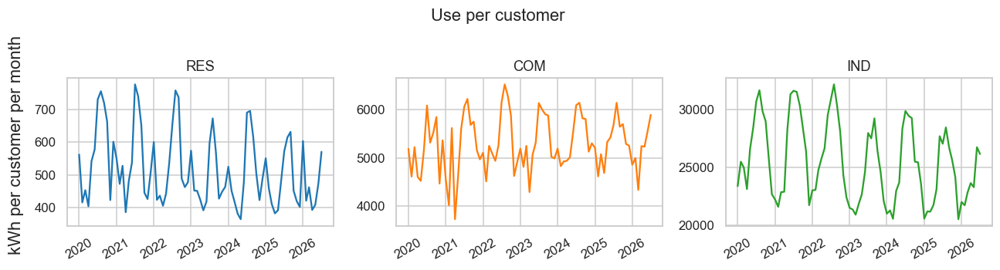

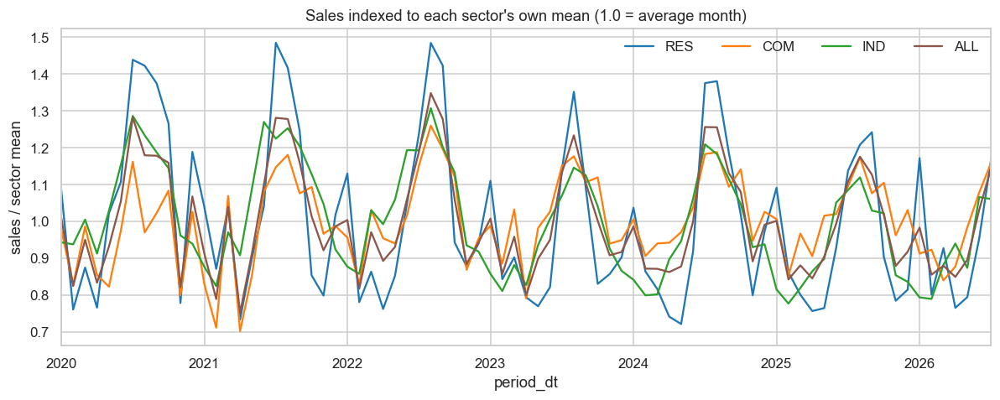

In [ ]:
small_multiples(eia, "sales", "Electricity sales by sector", "million kWh")
small_multiples(eia, "price", "Average retail price by sector", "cents per kWh")
small_multiples(eia, "revenue", "Retail revenue by sector", "million dollars")
small_multiples(
    eia[eia["customers"] > 0],
    "customers",
    "Customer counts (log scale, OTH dropped because it is zero)",
    "customers",
    sectors=["RES", "COM", "IND", "TRA", "ALL"],
    logy=True,
)
small_multiples(
    eia[eia["sectorid"].isin(["RES", "COM", "IND"])],
    "kwh_per_customer",
    "Use per customer",
    "kWh per customer per month",
    sectors=["RES", "COM", "IND"],
)

indexed = (
    eia[eia["sectorid"].isin(MAIN_SECTORS)]
    .assign(index=lambda frame: frame["sales"] / frame.groupby("sectorid")["sales"].transform("mean"))
    .pivot(index="period_dt", columns="sectorid", values="index")[MAIN_SECTORS]
)
ax = indexed.plot(
    figsize=(11, 4.5),
    color=[SECTOR_COLORS[sector] for sector in MAIN_SECTORS],
    title="Sales indexed to each sector's own mean (1.0 = average month)",
)
ax.set_ylabel("sales / sector mean")
ax.legend(title=None, ncol=4, frameon=False)
ax.figure.tight_layout()


Text(0.5, 0.98, 'Price versus sales, colored by month')

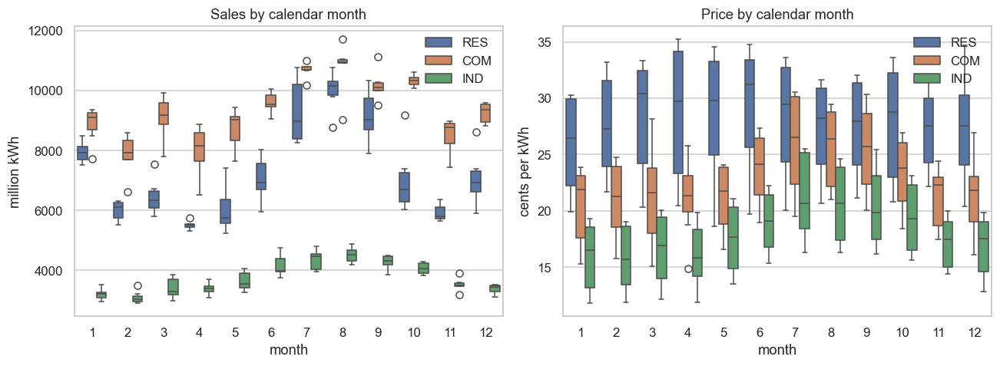

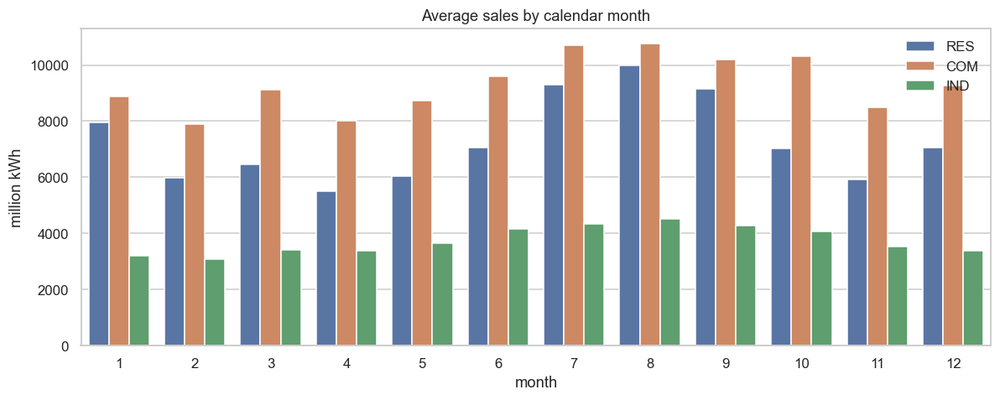

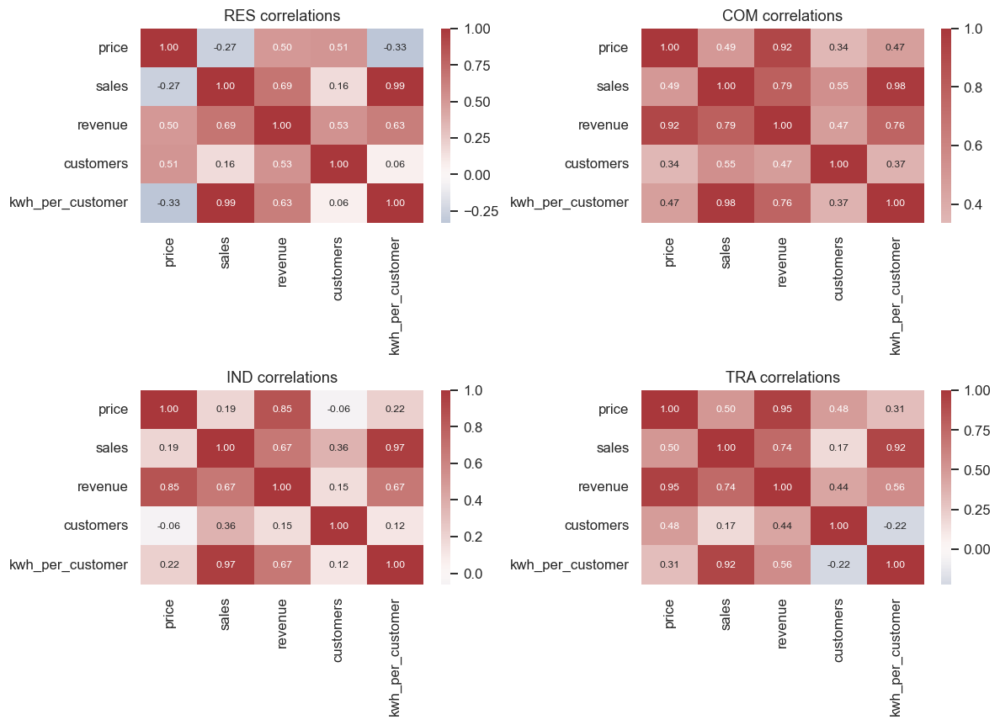

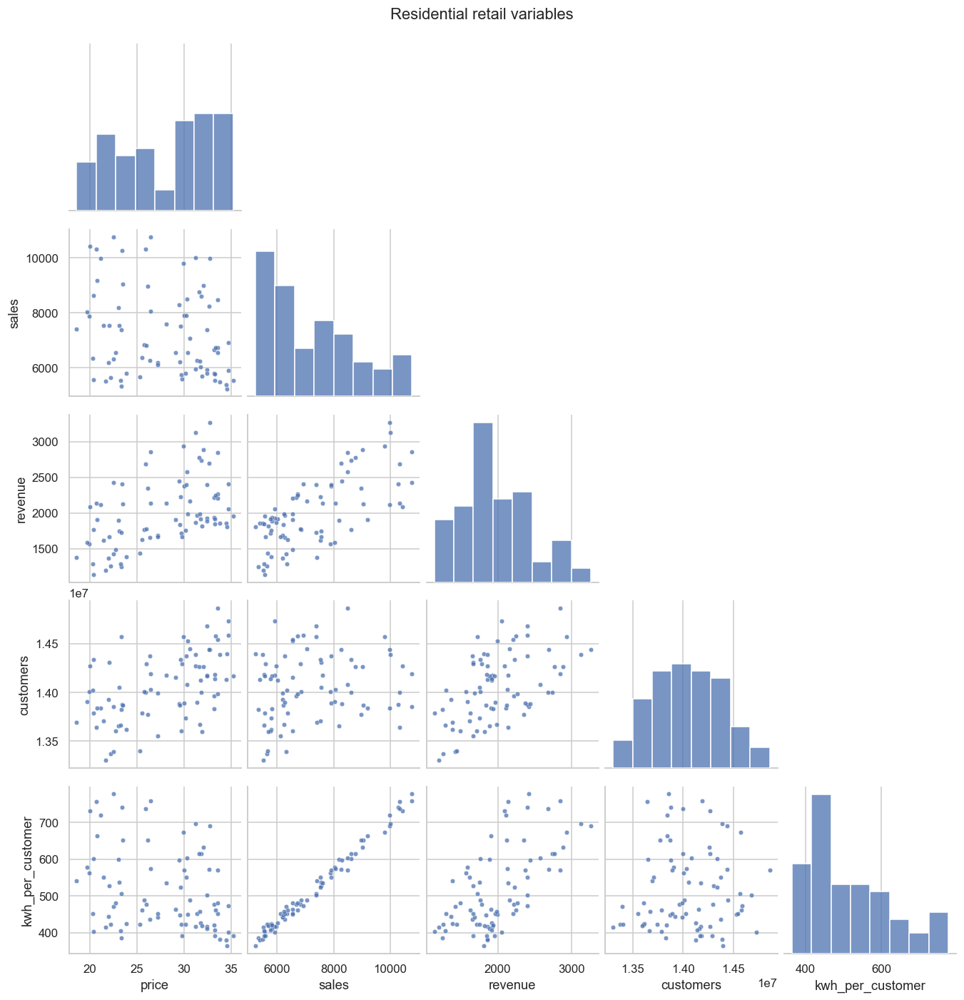

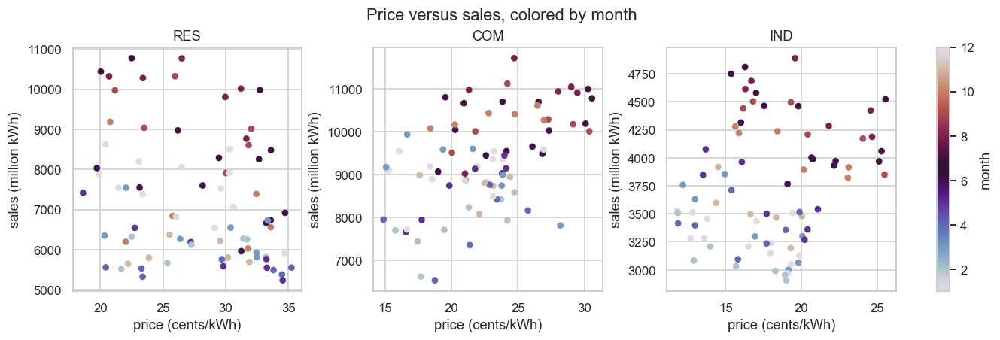

In [ ]:
season = eia[eia["sectorid"].isin(["RES", "COM", "IND"])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=season, x="month", y="sales", hue="sectorid", hue_order=["RES", "COM", "IND"], ax=axes[0])
axes[0].set_title("Sales by calendar month")
axes[0].set_ylabel("million kWh")
sns.boxplot(data=season, x="month", y="price", hue="sectorid", hue_order=["RES", "COM", "IND"], ax=axes[1])
axes[1].set_title("Price by calendar month")
axes[1].set_ylabel("cents per kWh")
for ax in axes:
    ax.legend(title=None, frameon=False)
fig.tight_layout()

month_means = (
    eia[eia["sectorid"].isin(["RES", "COM", "IND"])]
    .groupby(["month", "sectorid"], as_index=False)["sales"]
    .mean()
)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=month_means, x="month", y="sales", hue="sectorid", hue_order=["RES", "COM", "IND"], ax=ax)
ax.set_title("Average sales by calendar month")
ax.set_ylabel("million kWh")
ax.legend(title=None, frameon=False)
fig.tight_layout()

eia_cols = ["price", "sales", "revenue", "customers", "kwh_per_customer"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, sector in zip(axes.ravel(), ["RES", "COM", "IND", "TRA"]):
    corr = eia.loc[eia["sectorid"] == sector, eia_cols].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"{sector} correlations")
fig.tight_layout()

res = eia[eia["sectorid"] == "RES"]
grid = sns.pairplot(res[eia_cols], corner=True, diag_kind="hist", plot_kws={"s": 18, "alpha": 0.75})
grid.fig.suptitle("Residential retail variables", y=1.02)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, sector in zip(axes, ["RES", "COM", "IND"]):
    part = eia[eia["sectorid"] == sector]
    scatter = ax.scatter(part["price"], part["sales"], c=part["month"], cmap="twilight", s=22)
    ax.set_title(sector)
    ax.set_xlabel("price (cents/kWh)")
    ax.set_ylabel("sales (million kWh)")
fig.colorbar(scatter, ax=axes, label="month", fraction=0.03)
fig.suptitle("Price versus sales, colored by month")


## Weather, on its own

Daily points are the San Diego grid cell. Monthly series are what can line up with EIA. Radiation and sunshine move together, and so do mean temperature, CDD, and HDD. Those clusters matter later: they are one signal recorded several ways, not separate drivers.


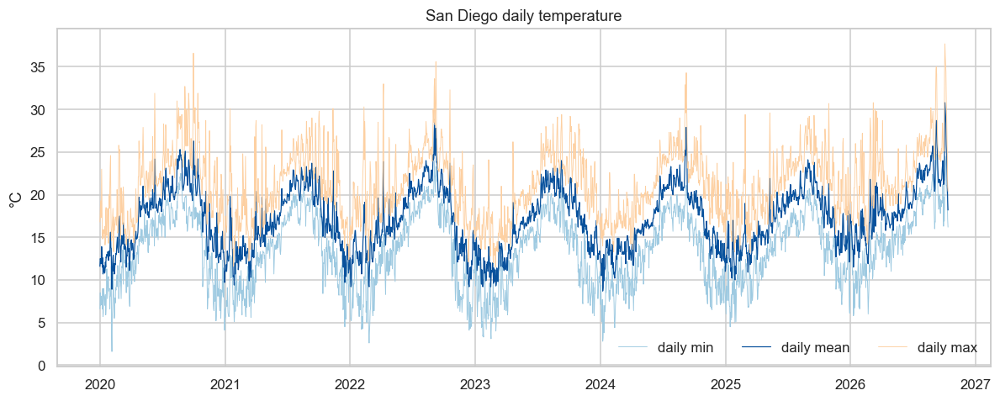

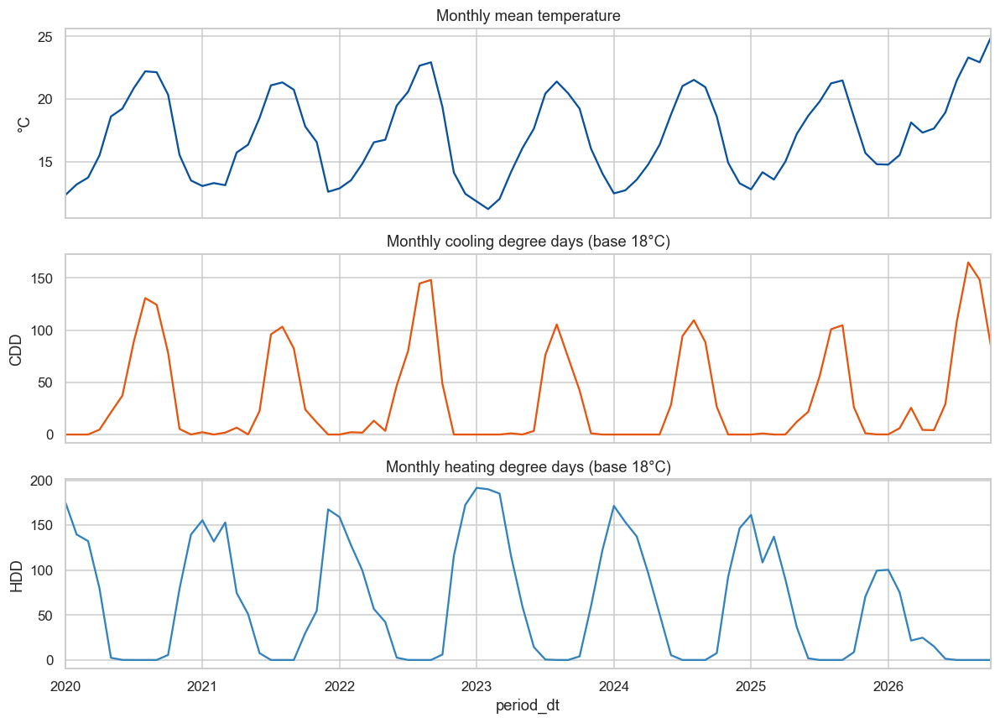

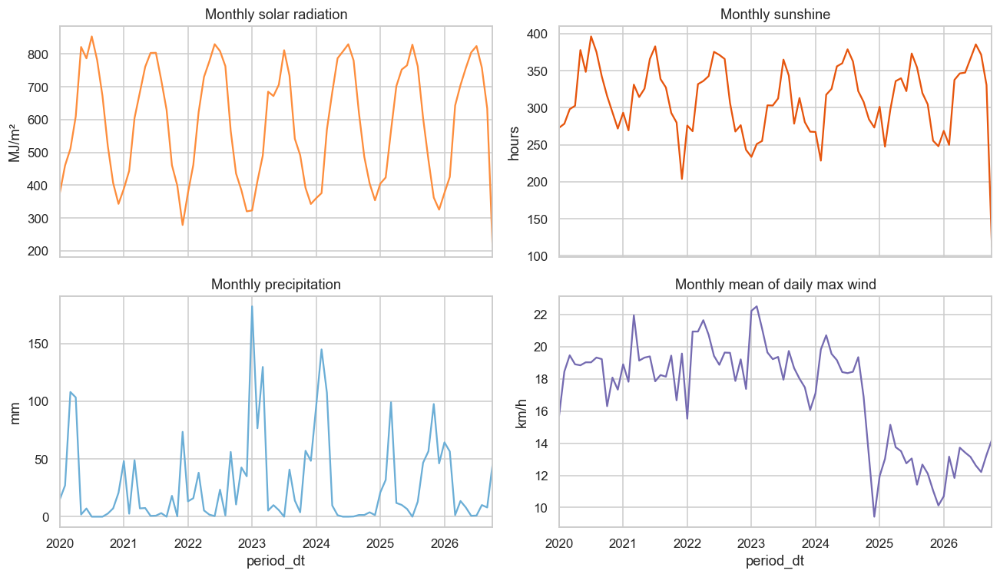

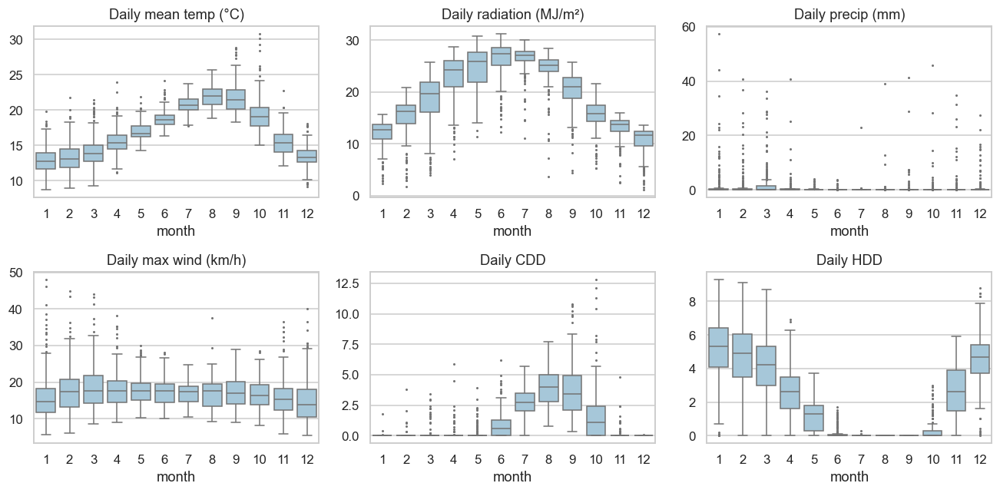

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily["time"], daily["temperature_2m_min"], color="#9ecae1", linewidth=0.6, label="daily min")
ax.plot(daily["time"], daily["temperature_2m_mean"], color="#08519c", linewidth=0.8, label="daily mean")
ax.plot(daily["time"], daily["temperature_2m_max"], color="#fdd0a2", linewidth=0.6, label="daily max")
ax.set_title("San Diego daily temperature")
ax.set_ylabel("°C")
ax.legend(ncol=3, frameon=False)
fig.tight_layout()

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
monthly_weather.set_index("period_dt")["temp_mean"].plot(ax=axes[0], color="#08519c", title="Monthly mean temperature")
axes[0].set_ylabel("°C")
monthly_weather.set_index("period_dt")["cdd"].plot(ax=axes[1], color="#e6550d", title="Monthly cooling degree days (base 18°C)")
axes[1].set_ylabel("CDD")
monthly_weather.set_index("period_dt")["hdd"].plot(ax=axes[2], color="#3182bd", title="Monthly heating degree days (base 18°C)")
axes[2].set_ylabel("HDD")
fig.tight_layout()

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
monthly_weather.set_index("period_dt")["radiation_mj"].plot(ax=axes[0, 0], title="Monthly solar radiation", color="#fd8d3c")
axes[0, 0].set_ylabel("MJ/m²")
monthly_weather.set_index("period_dt")["sunshine_hours"].plot(ax=axes[0, 1], title="Monthly sunshine", color="#e6550d")
axes[0, 1].set_ylabel("hours")
monthly_weather.set_index("period_dt")["precip_mm"].plot(ax=axes[1, 0], title="Monthly precipitation", color="#6baed6")
axes[1, 0].set_ylabel("mm")
monthly_weather.set_index("period_dt")["wind_mean"].plot(ax=axes[1, 1], title="Monthly mean of daily max wind", color="#756bb1")
axes[1, 1].set_ylabel("km/h")
fig.tight_layout()

weather_month_vars = [
    ("temperature_2m_mean", "Daily mean temp (°C)"),
    ("shortwave_radiation_sum", "Daily radiation (MJ/m²)"),
    ("precipitation_sum", "Daily precip (mm)"),
    ("wind_speed_10m_max", "Daily max wind (km/h)"),
    ("cdd", "Daily CDD"),
    ("hdd", "Daily HDD"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (column, label) in zip(axes.ravel(), weather_month_vars):
    sns.boxplot(data=daily, x="month", y=column, ax=ax, color="#9ecae1", fliersize=1)
    ax.set_title(label)
    ax.set_xlabel("month")
    ax.set_ylabel("")
fig.tight_layout()


Text(0.5, 1.02, 'Monthly weather pair plot')

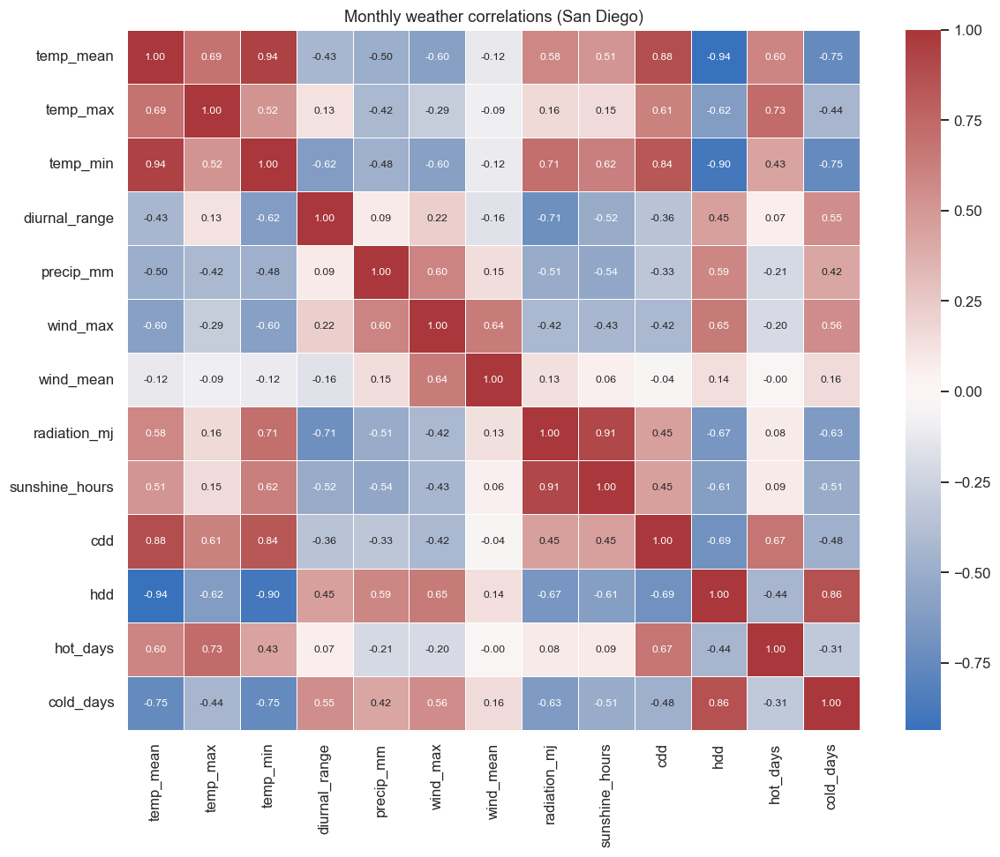

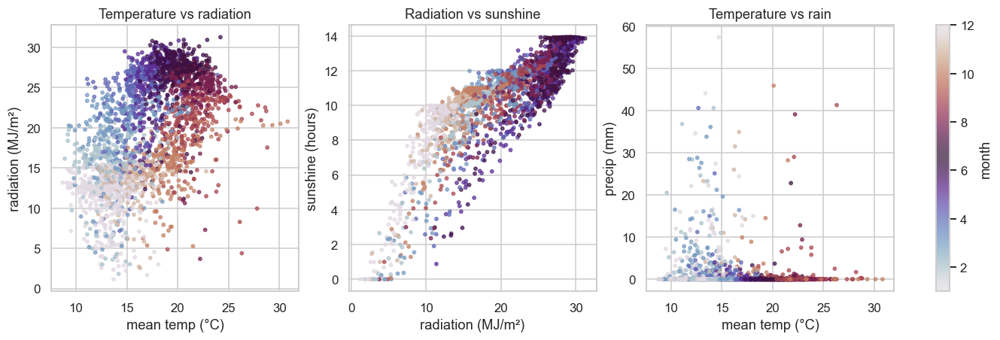

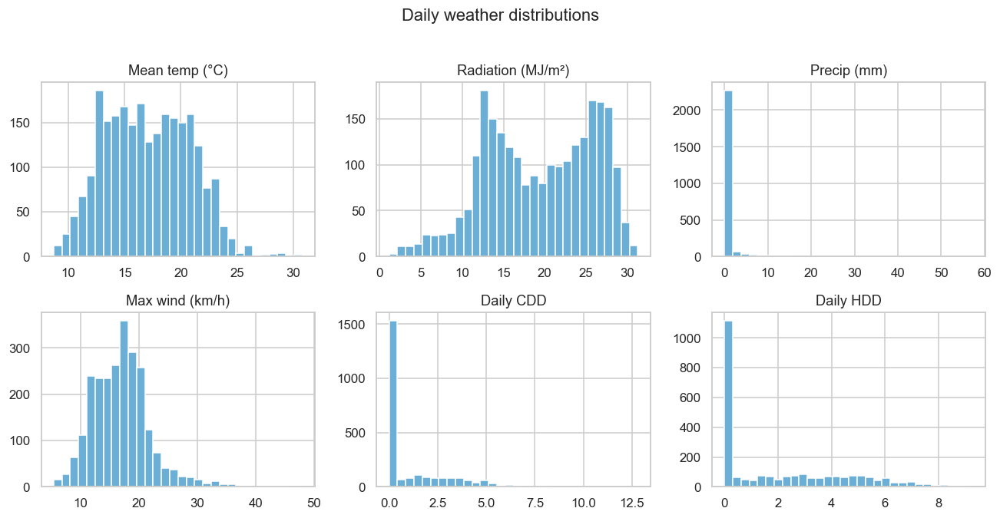

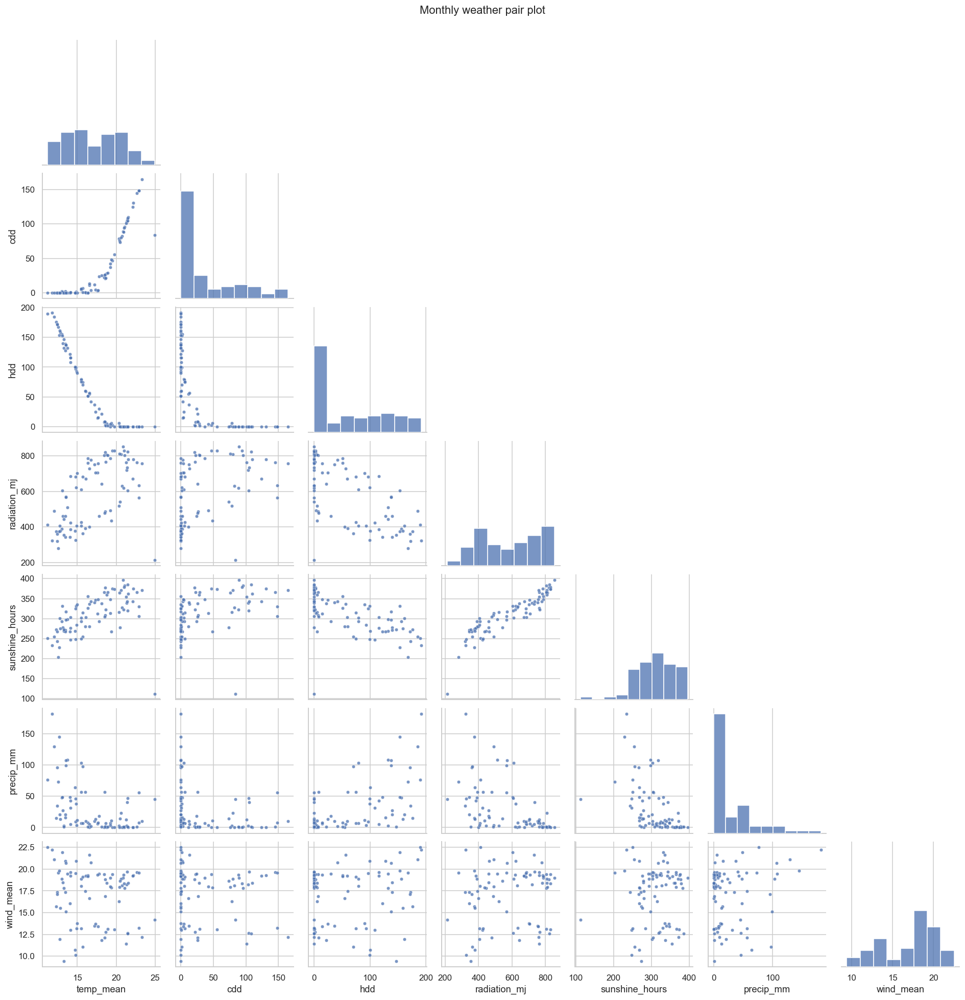

In [8]:
heatmap(
    monthly_weather[WX].corr(),
    "Monthly weather correlations (San Diego)",
    figsize=(11, 9),
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
axes[0].scatter(daily["temperature_2m_mean"], daily["shortwave_radiation_sum"], c=daily["month"], cmap="twilight", s=8, alpha=0.7)
axes[0].set_xlabel("mean temp (°C)")
axes[0].set_ylabel("radiation (MJ/m²)")
axes[0].set_title("Temperature vs radiation")
axes[1].scatter(daily["shortwave_radiation_sum"], daily["sunshine_hours"], c=daily["month"], cmap="twilight", s=8, alpha=0.7)
axes[1].set_xlabel("radiation (MJ/m²)")
axes[1].set_ylabel("sunshine (hours)")
axes[1].set_title("Radiation vs sunshine")
scatter = axes[2].scatter(daily["temperature_2m_mean"], daily["precipitation_sum"], c=daily["month"], cmap="twilight", s=8, alpha=0.7)
axes[2].set_xlabel("mean temp (°C)")
axes[2].set_ylabel("precip (mm)")
axes[2].set_title("Temperature vs rain")
fig.colorbar(scatter, ax=axes, label="month", fraction=0.03)

hist_cols = [
    ("temperature_2m_mean", "Mean temp (°C)"),
    ("shortwave_radiation_sum", "Radiation (MJ/m²)"),
    ("precipitation_sum", "Precip (mm)"),
    ("wind_speed_10m_max", "Max wind (km/h)"),
    ("cdd", "Daily CDD"),
    ("hdd", "Daily HDD"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (column, label) in zip(axes.ravel(), hist_cols):
    ax.hist(daily[column], bins=30, color="#6baed6", edgecolor="white")
    ax.set_title(label)
fig.suptitle("Daily weather distributions", y=1.02)
fig.tight_layout()

grid = sns.pairplot(
    monthly_weather[["temp_mean", "cdd", "hdd", "radiation_mj", "sunshine_hours", "precip_mm", "wind_mean"]],
    corner=True,
    diag_kind="hist",
    plot_kws={"s": 18, "alpha": 0.75},
)
grid.fig.suptitle("Monthly weather pair plot", y=1.02)


## The two datasets together

EIA is monthly and statewide. Weather is aggregated to the same month, then merged on `period`. The first heatmaps are ordinary correlations, so a shared seasonal cycle counts as a relationship. The adjusted heatmap subtracts each variable's month-of-year average first. Whatever is still colored there is the part a model can use on top of a month effect.

`kWh per customer` is sales with the slow growth in customer counts taken out. For residential it tracks sales almost 1:1, because the customer base barely moves relative to the seasonal swing.


Sales vs weather


,temp_mean,temp_max,temp_min,diurnal_range,precip_mm,wind_max,wind_mean,radiation_mj,sunshine_hours,cdd,hdd,hot_days,cold_days
RES,0.63,0.35,0.61,-0.24,-0.19,-0.26,0.07,0.29,0.42,0.84,-0.40,0.43,-0.14
COM,0.66,0.25,0.62,-0.36,-0.16,-0.40,-0.04,0.33,0.41,0.70,-0.53,0.23,-0.36
IND,0.84,0.51,0.80,-0.46,-0.49,-0.37,0.25,0.60,0.67,0.80,-0.76,0.43,-0.55
TRA,0.21,-0.05,0.20,-0.14,-0.02,-0.23,-0.15,0.04,-0.03,0.20,-0.18,0.00,-0.21
ALL,0.75,0.38,0.72,-0.35,-0.26,-0.36,0.07,0.40,0.51,0.88,-0.57,0.40,-0.32


Sales vs weather, month-of-year average removed


,temp_mean,temp_max,temp_min,diurnal_range,precip_mm,wind_max,wind_mean,radiation_mj,sunshine_hours,cdd,hdd,hot_days,cold_days
RES,0.27,0.24,0.19,0.06,-0.06,0.07,0.24,0.25,0.26,0.59,-0.03,0.30,0.08
COM,-0.13,-0.18,-0.13,-0.17,0.23,-0.09,-0.04,-0.25,-0.18,-0.03,0.16,-0.33,-0.02
IND,0.12,0.28,-0.05,0.07,-0.24,0.22,0.49,0.26,0.28,0.31,0.02,0.20,0.10
TRA,-0.17,-0.36,-0.06,-0.11,0.06,-0.20,-0.22,-0.33,-0.36,-0.26,0.07,-0.33,-0.10
ALL,0.14,0.13,0.04,-0.04,0.03,0.05,0.26,0.09,0.14,0.46,0.07,0.07,0.07


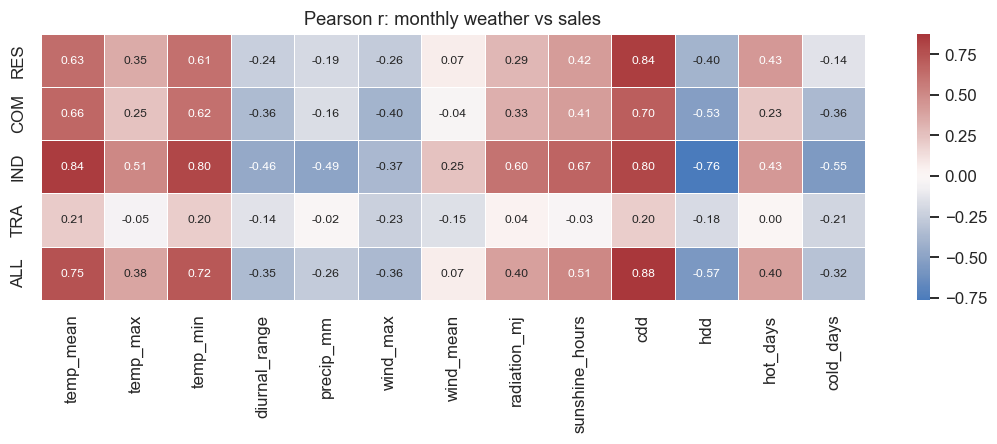

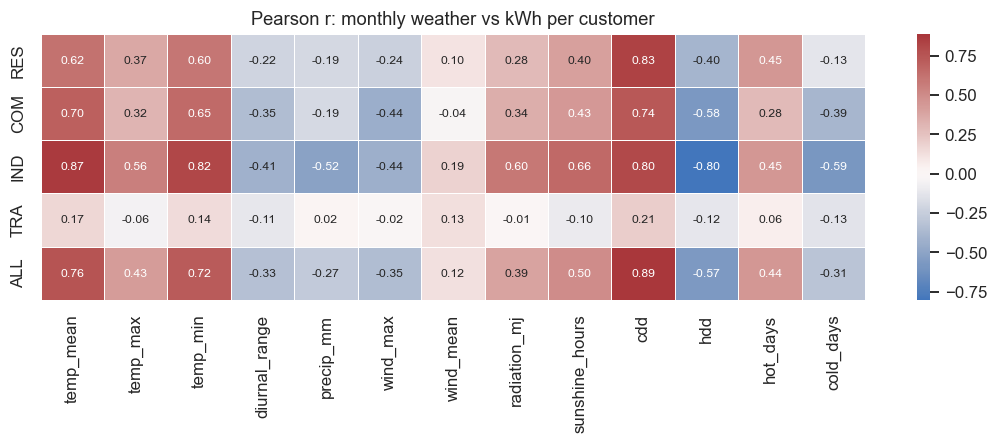

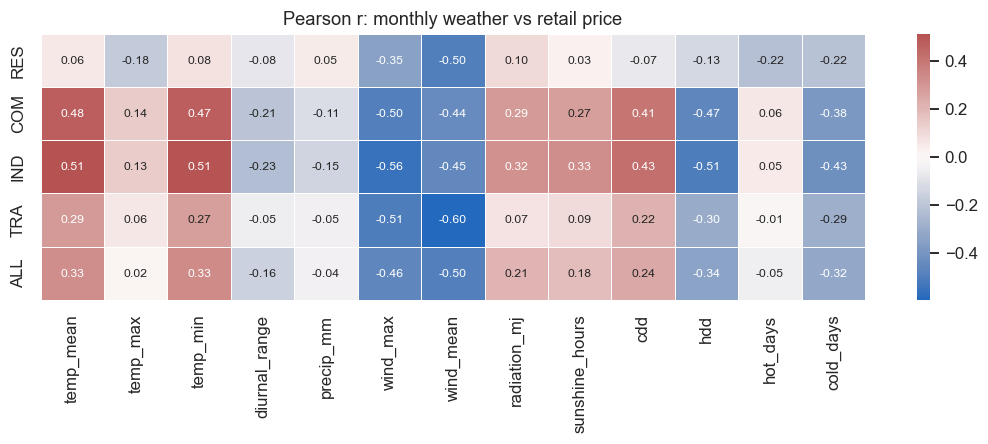

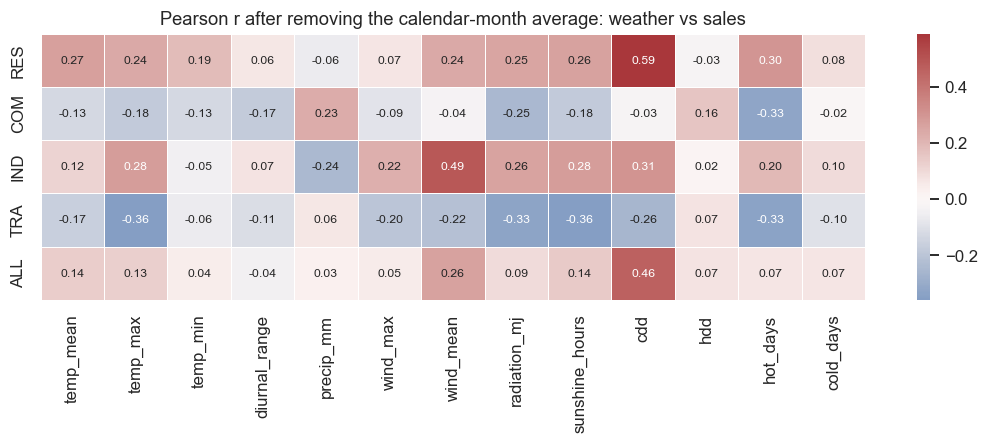

In [9]:
sales_corr = cross_corr(panel, "sales")
kwh_corr = cross_corr(panel, "kwh_per_customer")
price_corr = cross_corr(panel, "price")
sales_adj = month_adjusted_corr(panel, "sales")

heatmap(sales_corr, "Pearson r: monthly weather vs sales")
heatmap(kwh_corr, "Pearson r: monthly weather vs kWh per customer")
heatmap(price_corr, "Pearson r: monthly weather vs retail price")
heatmap(sales_adj, "Pearson r after removing the calendar-month average: weather vs sales")

print("Sales vs weather")
display(sales_corr.round(2))
print("Sales vs weather, month-of-year average removed")
display(sales_adj.round(2))


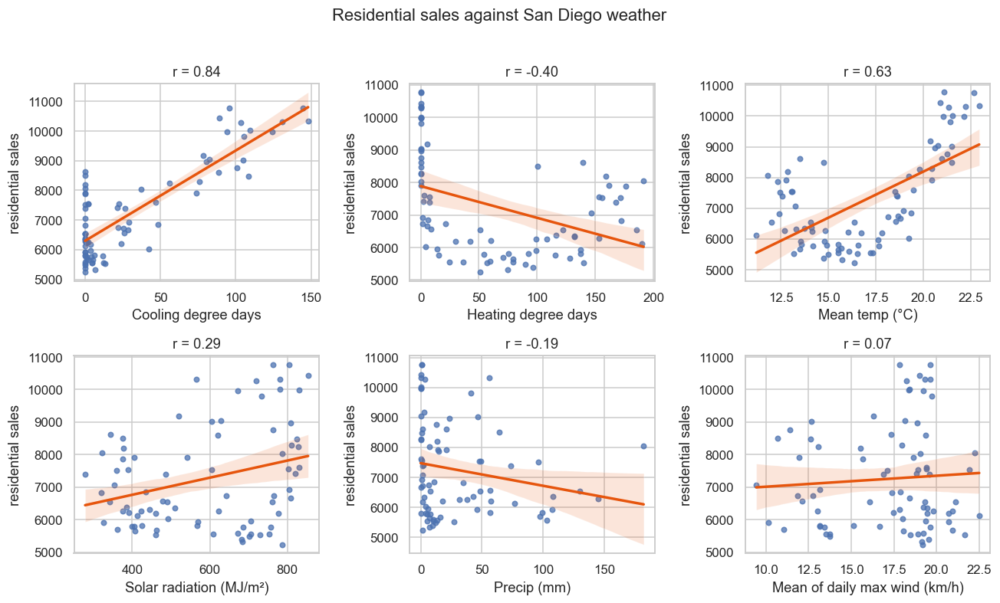

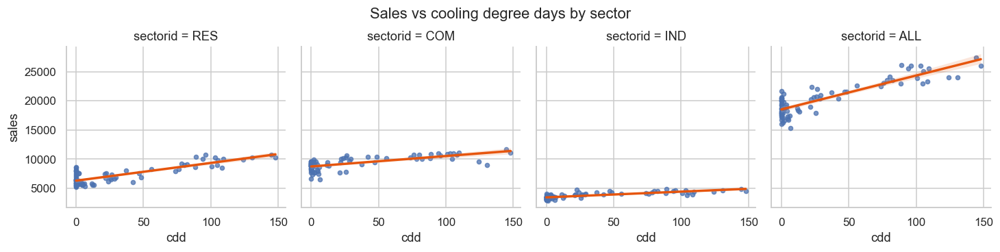

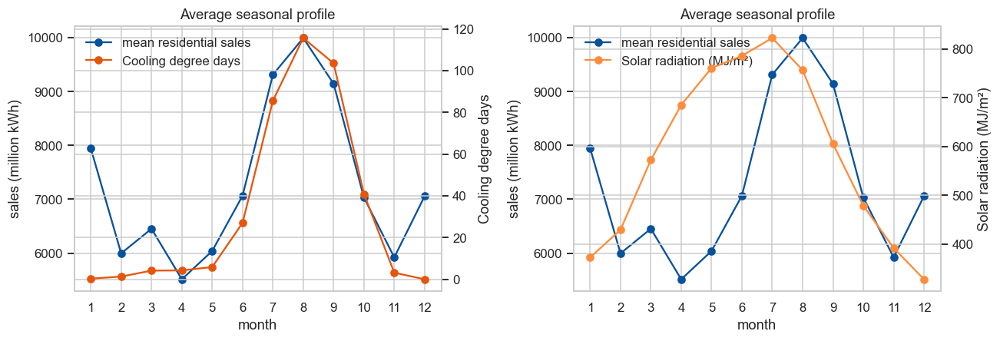

In [10]:
res = panel[panel["sectorid"] == "RES"].sort_values("period_dt")
features = ["cdd", "hdd", "temp_mean", "radiation_mj", "precip_mm", "wind_mean"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, feature in zip(axes.ravel(), features):
    sns.regplot(data=res, x=feature, y="sales", ax=ax, scatter_kws={"s": 18, "alpha": 0.75}, line_kws={"color": "#e6550d"})
    r = res["sales"].corr(res[feature])
    ax.set_title(f"r = {r:.2f}")
    ax.set_xlabel(WX_LABELS[feature])
    ax.set_ylabel("residential sales")
fig.suptitle("Residential sales against San Diego weather", y=1.02)
fig.tight_layout()

sns.lmplot(
    data=panel[panel["sectorid"].isin(MAIN_SECTORS)],
    x="cdd",
    y="sales",
    col="sectorid",
    col_order=MAIN_SECTORS,
    height=3.2,
    aspect=1.05,
    scatter_kws={"s": 16, "alpha": 0.75},
    line_kws={"color": "#e6550d"},
).fig.suptitle("Sales vs cooling degree days by sector", y=1.04)

profile = res.groupby("month").agg(
    sales=("sales", "mean"),
    cdd=("cdd", "mean"),
    hdd=("hdd", "mean"),
    temp_mean=("temp_mean", "mean"),
    radiation_mj=("radiation_mj", "mean"),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, feature, color in (
    (axes[0], "cdd", "#e6550d"),
    (axes[1], "radiation_mj", "#fd8d3c"),
):
    ax.plot(profile.index, profile["sales"], color="#08519c", marker="o", label="mean residential sales")
    twin = ax.twinx()
    twin.plot(profile.index, profile[feature], color=color, marker="o", label=WX_LABELS[feature])
    ax.set_xlabel("month")
    ax.set_ylabel("sales (million kWh)")
    twin.set_ylabel(WX_LABELS[feature])
    ax.set_xticks(range(1, 13))
    ax.set_title("Average seasonal profile")
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = twin.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, frameon=False, loc="upper left")
fig.tight_layout()


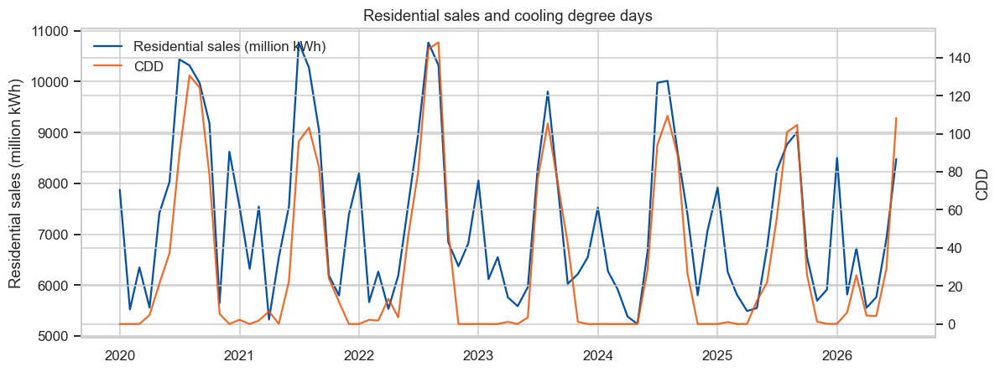

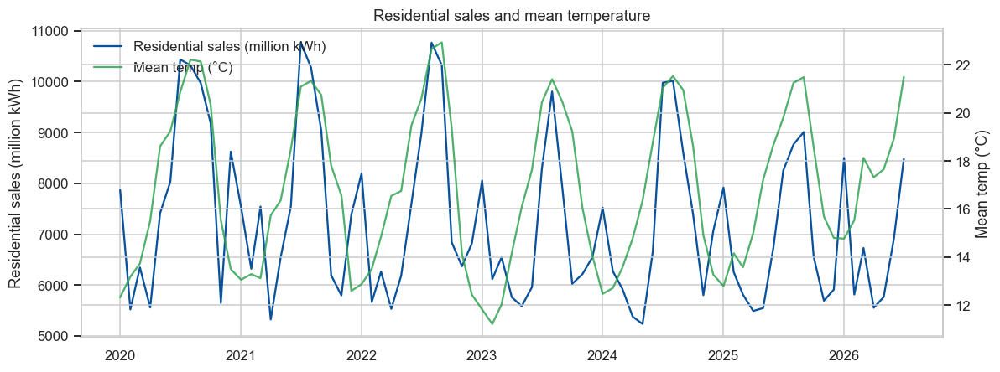

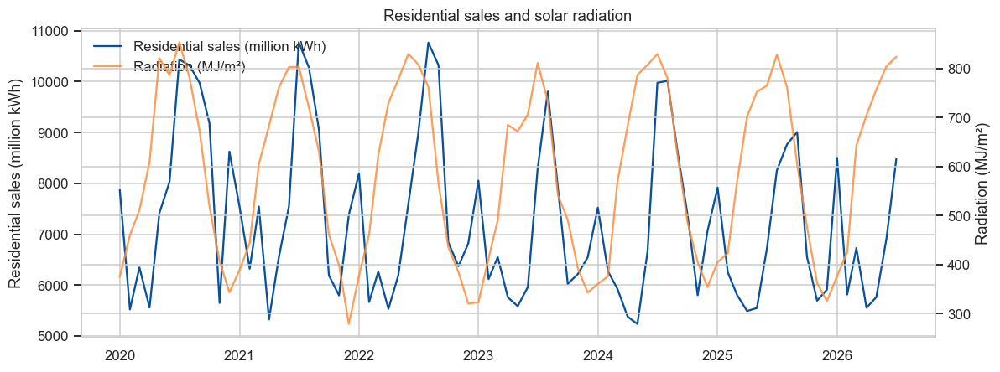

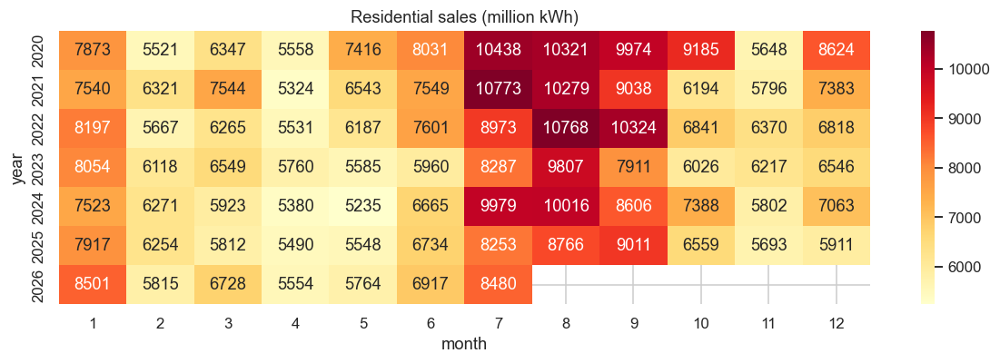

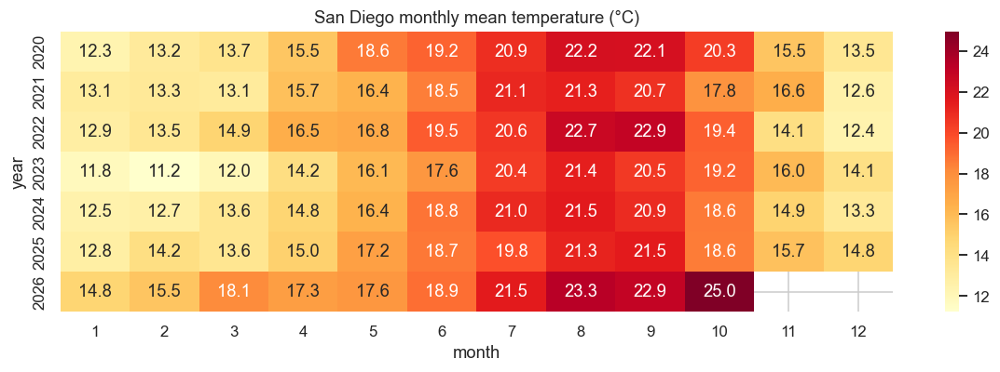

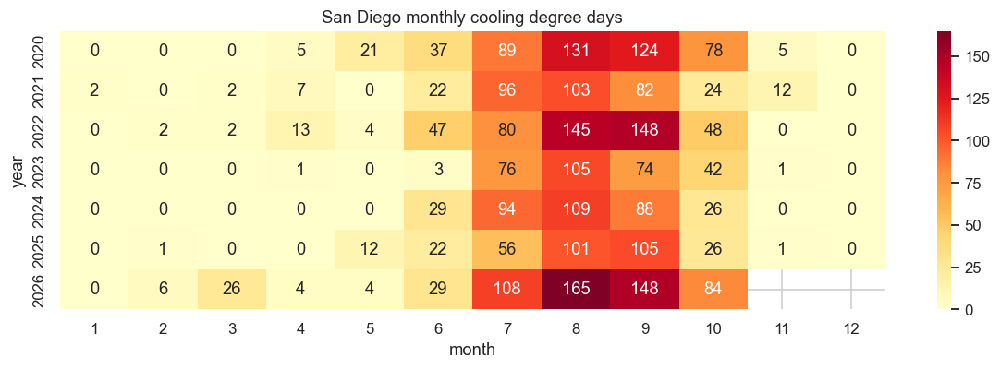

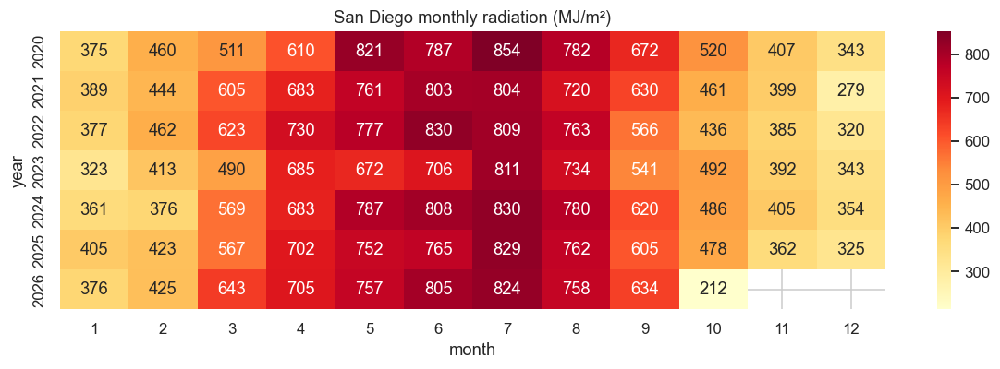

In [11]:
res = panel[panel["sectorid"] == "RES"].sort_values("period_dt")

def twin_series(frame, left, right, left_label, right_label, title, right_color):
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.plot(frame["period_dt"], frame[left], color="#08519c", label=left_label)
    twin = ax.twinx()
    twin.plot(frame["period_dt"], frame[right], color=right_color, alpha=0.85, label=right_label)
    ax.set_ylabel(left_label)
    twin.set_ylabel(right_label)
    ax.set_title(title)
    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = twin.get_legend_handles_labels()
    ax.legend(lines + lines2, labels + labels2, frameon=False, loc="upper left")
    fig.tight_layout()

twin_series(res, "sales", "cdd", "Residential sales (million kWh)", "CDD", "Residential sales and cooling degree days", "#e6550d")
twin_series(res, "sales", "temp_mean", "Residential sales (million kWh)", "Mean temp (°C)", "Residential sales and mean temperature", "#31a354")
twin_series(res, "sales", "radiation_mj", "Residential sales (million kWh)", "Radiation (MJ/m²)", "Residential sales and solar radiation", "#fd8d3c")

def calendar(frame, value, title, fmt):
    pivot = frame.pivot(index="year", columns="month", values=value)
    fig, ax = plt.subplots(figsize=(11, 3.8))
    sns.heatmap(pivot, annot=True, fmt=fmt, cmap="YlOrRd", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("month")
    fig.tight_layout()

calendar(res, "sales", "Residential sales (million kWh)", ".0f")
calendar(monthly_weather, "temp_mean", "San Diego monthly mean temperature (°C)", ".1f")
calendar(monthly_weather, "cdd", "San Diego monthly cooling degree days", ".0f")
calendar(monthly_weather, "radiation_mj", "San Diego monthly radiation (MJ/m²)", ".0f")


Residential sales vs CDD, linear time trend removed: r = 0.84


Text(0.5, 1.02, 'Residential month: sales, price, and the weather features worth comparing')

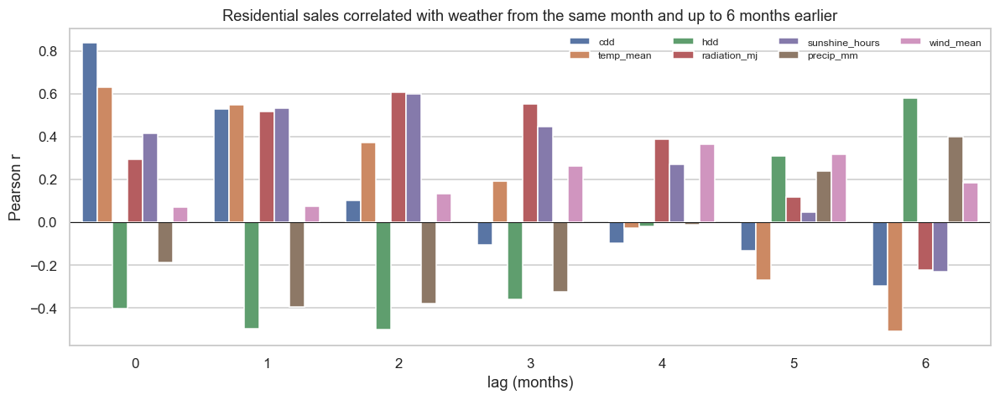

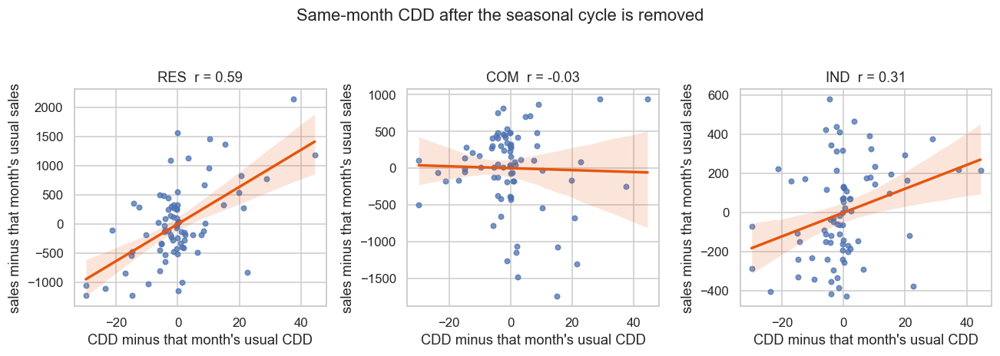

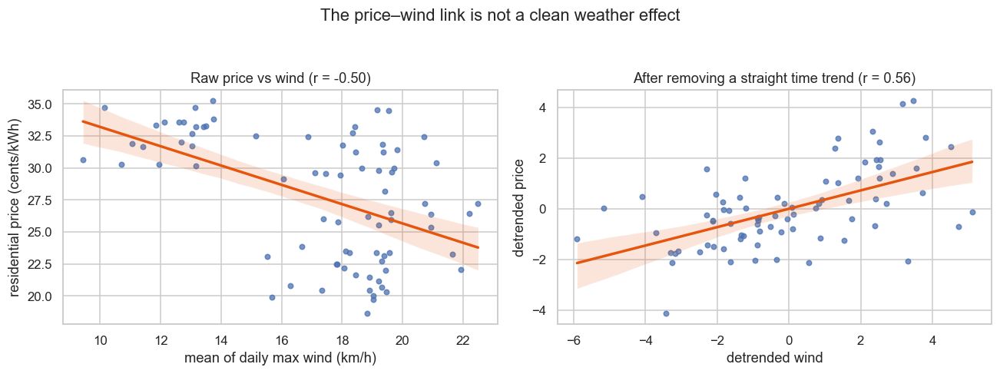

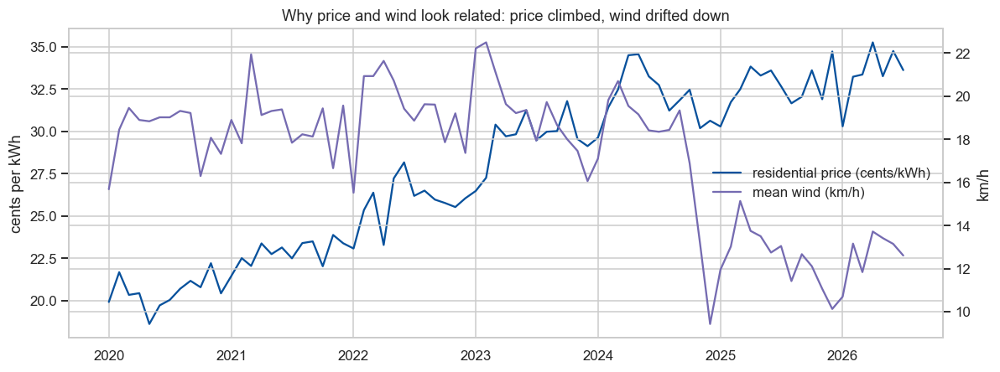

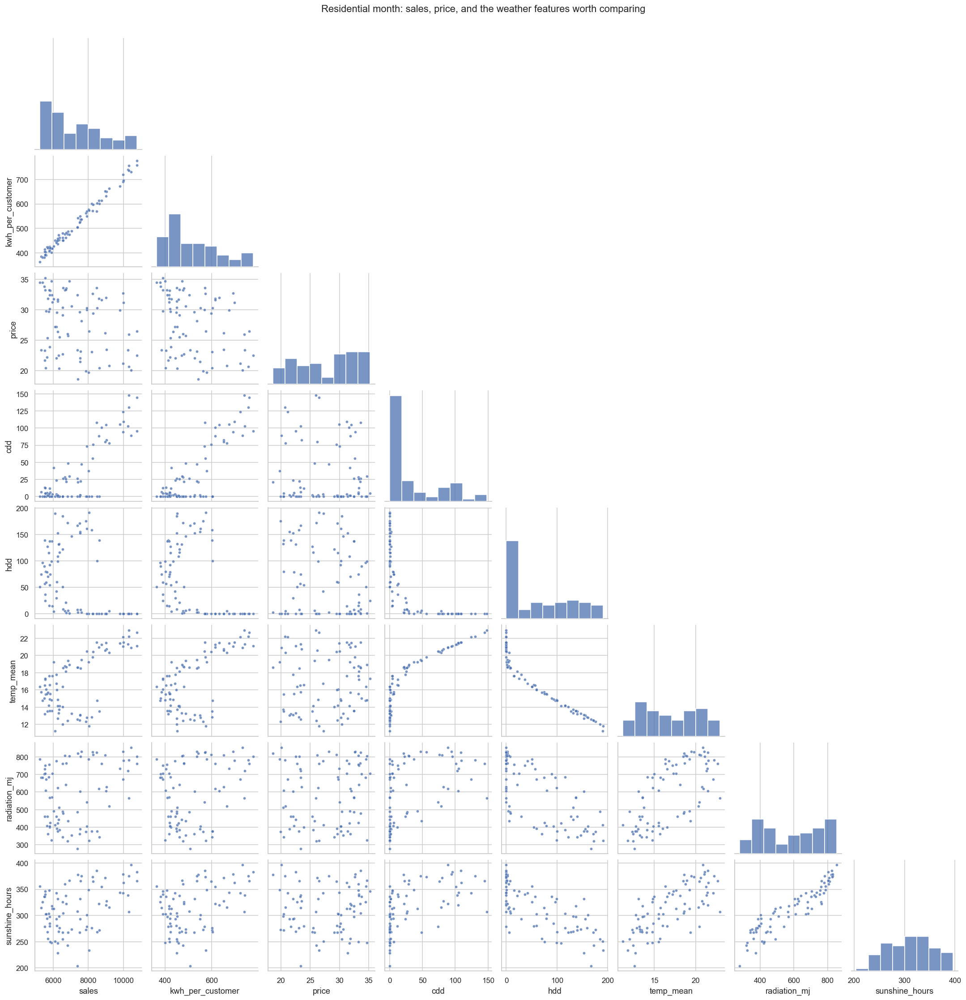

In [ ]:
res = panel[panel["sectorid"] == "RES"].sort_values("period_dt").copy()
lag_features = ["cdd", "temp_mean", "hdd", "radiation_mj", "sunshine_hours", "precip_mm", "wind_mean"]
lag_rows = []
for feature in lag_features:
    for lag in range(0, 7):
        lag_rows.append({"feature": feature, "lag_months": lag, "r": res["sales"].corr(res[feature].shift(lag))})
lags = pd.DataFrame(lag_rows)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=lags, x="lag_months", y="r", hue="feature", ax=ax)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("Residential sales correlated with weather from the same month and up to 6 months earlier")
ax.set_ylabel("Pearson r")
ax.set_xlabel("lag (months)")
ax.legend(ncol=4, frameon=False, fontsize=8)
fig.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=False)
for ax, sector in zip(axes, ["RES", "COM", "IND"]):
    group = panel[panel["sectorid"] == sector].copy()
    for column in ("sales", "cdd"):
        group[column] = group[column] - group.groupby("month")[column].transform("mean")
    sns.regplot(data=group, x="cdd", y="sales", ax=ax, scatter_kws={"s": 18, "alpha": 0.75}, line_kws={"color": "#e6550d"})
    r = group["sales"].corr(group["cdd"])
    ax.set_title(f"{sector}  r = {r:.2f}")
    ax.set_xlabel("CDD minus that month's usual CDD")
    ax.set_ylabel("sales minus that month's usual sales")
fig.suptitle("Same-month CDD after the seasonal cycle is removed", y=1.05)
fig.tight_layout()

# Price rose almost in a straight line. Mean wind drifted down. The raw price–wind
# correlation is mostly those two trends.
res["t"] = np.arange(len(res))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
raw_r = res["price"].corr(res["wind_mean"])
sns.regplot(data=res, x="wind_mean", y="price", ax=axes[0], scatter_kws={"s": 18, "alpha": 0.75}, line_kws={"color": "#e6550d"})
axes[0].set_title(f"Raw price vs wind (r = {raw_r:.2f})")
axes[0].set_xlabel("mean of daily max wind (km/h)")
axes[0].set_ylabel("residential price (cents/kWh)")

detrended = res.copy()
for column in ("price", "wind_mean", "sales", "cdd"):
    slope, intercept = np.polyfit(detrended["t"], detrended[column], 1)
    detrended[column] = detrended[column] - (slope * detrended["t"] + intercept)
detrended_r = detrended["price"].corr(detrended["wind_mean"])
cdd_r = detrended["sales"].corr(detrended["cdd"])
sns.regplot(data=detrended, x="wind_mean", y="price", ax=axes[1], scatter_kws={"s": 18, "alpha": 0.75}, line_kws={"color": "#e6550d"})
axes[1].set_title(f"After removing a straight time trend (r = {detrended_r:.2f})")
axes[1].set_xlabel("detrended wind")
axes[1].set_ylabel("detrended price")
fig.suptitle("The price–wind link is not a clean weather effect", y=1.05)
fig.tight_layout()
print(f"Residential sales vs CDD, linear time trend removed: r = {cdd_r:.2f}")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(res["period_dt"], res["price"], color="#08519c", label="residential price (cents/kWh)")
twin = ax.twinx()
twin.plot(res["period_dt"], res["wind_mean"], color="#756bb1", label="mean wind (km/h)")
ax.set_title("Why price and wind look related: price climbed, wind drifted down")
ax.set_ylabel("cents per kWh")
twin.set_ylabel("km/h")
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = twin.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, frameon=False, loc="center right")
fig.tight_layout()

joined = res[["sales", "kwh_per_customer", "price", "cdd", "hdd", "temp_mean", "radiation_mj", "sunshine_hours"]]
grid = sns.pairplot(joined, corner=True, diag_kind="hist", plot_kws={"s": 16, "alpha": 0.75})
grid.fig.suptitle("Residential month: sales, price, and the weather features worth comparing", y=1.02)


## What is worth putting in a model

Numbers below are Pearson correlations on the California × San Diego monthly panel, January 2020 through July 2026 (79 months).

**Target.** Residential `sales` (million kWh). `kwh_per_customer` is almost the same series (r = 0.99 with sales) and is the one to use if you want customer growth out of the target. Commercial and industrial sales are usable second targets. Skip `OTH` (every value is 0). Transportation is about 56 million kWh a month and barely follows this weather.

**Use these**

- **Calendar month.** Residential sales peak in August (about 10,000 million kWh), bottom out in April (about 5,500), and have a smaller winter bump in December–January (about 7,000–7,900). A month feature is the baseline.
- **Same-month CDD.** Strongest weather feature. Residential r = 0.84, all-sectors 0.88, industrial 0.80, commercial 0.70. It still holds after a straight time trend is removed (residential r stays about 0.84) and after the calendar-month average is removed (residential r = 0.59, all-sectors 0.46, industrial 0.31). Commercial drops to about 0. The heat signal on top of season is a residential story.
- **Mean temperature, as a substitute for CDD, not a second feature.** Residential sales r = 0.63. Temperature and CDD move together (r = 0.88).

**Optional, and only one of them**

- **Sunshine hours or radiation.** They are the same solar signal (r = 0.91). Raw link to residential sales is moderate (sunshine 0.42, radiation 0.29). After removing the calendar month, both are about 0.25. Radiation's correlation is higher at a 2-month lag (r = 0.60) than in the same month (r = 0.29) because the sun peaks in June–July and residential sales peak in August. CDD already peaks with sales in August, so the lag is the seasonal offset, not a reason to delay the solar feature.

**Leave out of the first model**

- **HDD as an extra residual feature.** Raw residential r = −0.40, which is the winter. After the calendar month is removed, r is about 0. Mean temperature and HDD are nearly mirrors (r = −0.94).
- **Precipitation and wind as sales features.** Weak for residential sales. Industrial sales do show a residual link with mean wind (about 0.49 after the month average is removed). That is large enough to plot and too shaky to trust until it shows up with a statewide weather series.
- **Retail price as a weather outcome.** Residential price vs mean temperature is r = 0.06. Price vs time is r = 0.95: it climbed in a nearly straight line. Wind drifted down over the same years (r = −0.66 with time), which is why price and wind look related in the raw scatter. Price is a tariff series.
- **Stacking temperature, CDD, HDD, radiation, and sunshine in one linear model.** They repeat the same seasonal cycle. The model will split one signal across collinear columns.
- **`ALL` as a feature next to the sectors.** It is their total.

**A reasonable first specification.** Residential sales ~ month + CDD. Then try adding sunshine hours and see whether the error actually drops. Hold out a later year (2025 or 2026) rather than random months, because neighboring months are not independent.

**Geography.** This CDD is one coastal grid cell and the sales are all of California. The match is already strong, which is why it is good enough to start. Inland heat will not show up fully in the San Diego series. A Sacramento or Central Valley Open-Meteo pull is the check if the residual in summer still looks large.
